# **Morgan MODEL BUILDING**

# Morgan Fingerprint ML Workflow

```text
DPP4 Bioactivity Data
        │
        ▼
Data Cleaning and Preparation
        │
        ▼
Activity Classification
        │
        ▼
Morgan Fingerprint Generation
(Radius = 3, 2048 bits)
        │
        ▼
Train/Test Split
80% Training
20% Locked Test
        │
        ▼
Baseline ML Model Comparison
        │
        ▼
Calculate Performance Metrics
        │
        ▼
Automatic Top-5 Model Selection
        │
        ▼
Hyperparameter Tuning
(Training Set + Cross-Validation Only)
        │
        ▼
morgan_hyperparameter_tuning/
        │
        ▼
Automatic Top-3 Tuned Models
        │
        ▼
Soft Voting Ensemble
        │
        ▼
soft_voting/
        │
        ▼
Compare:
Best Individual Model
        VS
Soft Voting Model
        │
        ▼
Automatic Final Model Selection
        │
        ▼
grand_final_selection/
        │
        ▼
final_morgan_model.joblib
        │
        ▼
FINAL TEST-SET EVALUATION
        │
        ▼
Final Morgan Model
        │
        ▼
COCONUT Screening
```


Importing necessary libraries

In [18]:
# Models
from sklearn.linear_model import LogisticRegression, RidgeClassifier, Perceptron, SGDClassifier, ElasticNet, PassiveAggressiveClassifier, BayesianRidge
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, BaggingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC, NuSVC
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.utils import shuffle

# Model Evaluation
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef, classification_report, confusion_matrix, roc_curve, auc, make_scorer
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

# Utilities
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from itertools import cycle
import joblib

## **Load data**

In [19]:
df = pd.read_csv('morgan_3_2048.csv')

display(pd.concat([df.head(5), df.tail(5)]))

,pIC50,bioactivity_class,canonical_smiles,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,9.000000,Active,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,4.460297,Inactive,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,4.549751,Inactive,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,7.221849,Active,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.795880,Active,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3896,5.551294,Inactive,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3897,5.850781,Inactive,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3898,9.221849,Active,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3899,8.000000,Active,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3900,3.174379,Inactive,[N-]=[N+]=NC(CCOc1ccc(S(N)(=O)=O)cc1)C1COc2ccc...,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Defining new Activity column based on bioactivity class.

In [20]:
df['Activity'] = df['bioactivity_class'].apply(lambda x: 1 if x == 'Active' else 0)
df1 = df.drop(columns=['pIC50', 'canonical_smiles', 'bioactivity_class'])

In [4]:
df1.head()

,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,...,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047,Activity
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


# **Data preparation**
## Data separation as X and y and spliting it to train and test set.

In [21]:
X = df1.drop(columns=['Activity'])
y = df1['Activity']

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=57, stratify=y)

# **Model Building**

### Defining Evaluation Function

In [6]:
def evaluate_model(model, X_train, y_train):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=25, random_state=57)

    # Compute ROC-AUC using cross_val_score
    auc_scores = cross_val_score(model, X_train, y_train, scoring="roc_auc", cv=cv, n_jobs=-1)
    results = {"ROC-AUC": f"{round(np.mean(auc_scores), 3)} ± {round(np.std(auc_scores), 3)}"}

    # Compute other metrics using cross_val_score
    for metric_name, scoring in [
        ("F1-score", "f1"),
        ("MCC", "matthews_corrcoef"),
        ("Accuracy", "accuracy"),
        ("Precision", "precision"),
        ("Sensitivity", "recall")
    ]:
        scores = cross_val_score(model, X_train, y_train, scoring=scoring, cv=cv, n_jobs=-1)
        results[metric_name] = f"{round(np.mean(scores), 3)} ± {round(np.std(scores), 3)}"

    return results

On the basis of this above function, We will implement it in model below and get the metrics from it.

## **Logistic Regression**

In [7]:
log_reg_results = evaluate_model(LogisticRegression(random_state=57), X_train, y_train)
log_reg_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/m

{'ROC-AUC': '0.871 ± 0.013',
 'F1-score': '0.82 ± 0.013',
 'MCC': '0.588 ± 0.03',
 'Accuracy': '0.797 ± 0.015',
 'Precision': '0.813 ± 0.017',
 'Sensitivity': '0.827 ± 0.022'}

## **Random Forest**


In [8]:
rf_results = evaluate_model(RandomForestClassifier(random_state=57), X_train, y_train)
rf_results

{'ROC-AUC': '0.894 ± 0.011',
 'F1-score': '0.842 ± 0.012',
 'MCC': '0.636 ± 0.026',
 'Accuracy': '0.821 ± 0.013',
 'Precision': '0.828 ± 0.015',
 'Sensitivity': '0.858 ± 0.019'}

## Ridge classifier

In [9]:
ridge_results = evaluate_model(RidgeClassifier(random_state=57), X_train, y_train)
ridge_results

{'ROC-AUC': '0.81 ± 0.016',
 'F1-score': '0.777 ± 0.015',
 'MCC': '0.496 ± 0.033',
 'Accuracy': '0.751 ± 0.016',
 'Precision': '0.777 ± 0.017',
 'Sensitivity': '0.778 ± 0.021'}

## SVC

In [10]:
svc_results = evaluate_model(SVC(probability=True, random_state=57), X_train, y_train)
svc_results

{'ROC-AUC': '0.891 ± 0.012',
 'F1-score': '0.843 ± 0.012',
 'MCC': '0.634 ± 0.029',
 'Accuracy': '0.82 ± 0.014',
 'Precision': '0.823 ± 0.015',
 'Sensitivity': '0.864 ± 0.019'}

## K-Nearest Neighbors (KNN)

In [11]:
knn_results = evaluate_model(KNeighborsClassifier(), X_train, y_train)
knn_results

{'ROC-AUC': '0.877 ± 0.013',
 'F1-score': '0.829 ± 0.013',
 'MCC': '0.61 ± 0.029',
 'Accuracy': '0.808 ± 0.014',
 'Precision': '0.822 ± 0.016',
 'Sensitivity': '0.837 ± 0.02'}

## Decision Tree


In [12]:
dt_results = evaluate_model(DecisionTreeClassifier(random_state=57), X_train, y_train)
dt_results

{'ROC-AUC': '0.767 ± 0.016',
 'F1-score': '0.79 ± 0.016',
 'MCC': '0.522 ± 0.034',
 'Accuracy': '0.764 ± 0.017',
 'Precision': '0.786 ± 0.016',
 'Sensitivity': '0.795 ± 0.027'}

## Naive Bayes

In [13]:
nb_results = evaluate_model(GaussianNB(), X_train, y_train)
nb_results

{'ROC-AUC': '0.766 ± 0.018',
 'F1-score': '0.729 ± 0.021',
 'MCC': '0.44 ± 0.035',
 'Accuracy': '0.717 ± 0.018',
 'Precision': '0.781 ± 0.018',
 'Sensitivity': '0.684 ± 0.031'}

## Gradient Boosting

In [14]:
gb_results = evaluate_model(GradientBoostingClassifier(random_state=57), X_train, y_train)
gb_results

{'ROC-AUC': '0.86 ± 0.014',
 'F1-score': '0.809 ± 0.014',
 'MCC': '0.552 ± 0.033',
 'Accuracy': '0.78 ± 0.016',
 'Precision': '0.784 ± 0.017',
 'Sensitivity': '0.836 ± 0.022'}

## AdaBoost

In [15]:
ada_boost_results = evaluate_model(AdaBoostClassifier(random_state=57), X_train, y_train)
ada_boost_results

{'ROC-AUC': '0.77 ± 0.017',
 'F1-score': '0.745 ± 0.017',
 'MCC': '0.39 ± 0.036',
 'Accuracy': '0.701 ± 0.017',
 'Precision': '0.711 ± 0.018',
 'Sensitivity': '0.784 ± 0.036'}

## NuSVC

In [16]:
nusvc_results = evaluate_model(NuSVC(probability=True, random_state=57), X_train, y_train)
nusvc_results

{'ROC-AUC': '0.893 ± 0.012',
 'F1-score': '0.846 ± 0.013',
 'MCC': '0.642 ± 0.029',
 'Accuracy': '0.824 ± 0.014',
 'Precision': '0.827 ± 0.015',
 'Sensitivity': '0.866 ± 0.02'}

## HistGradientBoostingClassifier

In [17]:
hist_gb_results = evaluate_model(HistGradientBoostingClassifier(random_state=57), X_train, y_train)
hist_gb_results

{'ROC-AUC': '0.888 ± 0.012',
 'F1-score': '0.833 ± 0.014',
 'MCC': '0.617 ± 0.031',
 'Accuracy': '0.811 ± 0.015',
 'Precision': '0.823 ± 0.017',
 'Sensitivity': '0.843 ± 0.02'}

## BernoulliNB

In [18]:
bernoulli_nb_results = evaluate_model(BernoulliNB(), X_train, y_train)
bernoulli_nb_results

{'ROC-AUC': '0.813 ± 0.017',
 'F1-score': '0.729 ± 0.022',
 'MCC': '0.463 ± 0.037',
 'Accuracy': '0.724 ± 0.02',
 'Precision': '0.808 ± 0.02',
 'Sensitivity': '0.664 ± 0.031'}

##  NearestCentroid

In [19]:
nearest_centroid_results = evaluate_model(NearestCentroid(), X_train, y_train)
nearest_centroid_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviatio

{'ROC-AUC': '0.813 ± 0.017',
 'F1-score': '0.655 ± 0.02',
 'MCC': '0.341 ± 0.034',
 'Accuracy': '0.659 ± 0.017',
 'Precision': '0.753 ± 0.022',
 'Sensitivity': '0.58 ± 0.027'}

## Linear Discriminant Analysis (LDA)

In [20]:
lda_results = evaluate_model(LinearDiscriminantAnalysis(), X_train, y_train)
lda_results

{'ROC-AUC': '0.639 ± 0.025',
 'F1-score': '0.667 ± 0.02',
 'MCC': '0.27 ± 0.041',
 'Accuracy': '0.637 ± 0.02',
 'Precision': '0.684 ± 0.02',
 'Sensitivity': '0.652 ± 0.027'}

## Quadratic Discriminant Analysis (QDA)

In [21]:
qda_results = evaluate_model(QuadraticDiscriminantAnalysis(), X_train, y_train)
qda_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of p

{'ROC-AUC': '0.83 ± 0.016',
 'F1-score': '0.796 ± 0.017',
 'MCC': '0.528 ± 0.033',
 'Accuracy': '0.767 ± 0.016',
 'Precision': '0.779 ± 0.027',
 'Sensitivity': '0.818 ± 0.046'}

## Extra Trees Classifier

In [22]:
extra_trees_results = evaluate_model(ExtraTreesClassifier(random_state=57), X_train, y_train)
extra_trees_results

{'ROC-AUC': '0.883 ± 0.013',
 'F1-score': '0.843 ± 0.012',
 'MCC': '0.641 ± 0.027',
 'Accuracy': '0.823 ± 0.013',
 'Precision': '0.834 ± 0.016',
 'Sensitivity': '0.853 ± 0.019'}

## Passive Aggressive Classifier

In [23]:
pac_results = evaluate_model(PassiveAggressiveClassifier(random_state=57), X_train, y_train)
pac_results

{'ROC-AUC': '0.839 ± 0.014',
 'F1-score': '0.796 ± 0.015',
 'MCC': '0.536 ± 0.029',
 'Accuracy': '0.771 ± 0.014',
 'Precision': '0.79 ± 0.022',
 'Sensitivity': '0.804 ± 0.037'}

## Perceptron

In [24]:
perceptron_results = evaluate_model(Perceptron(random_state=57), X_train, y_train)
perceptron_results

{'ROC-AUC': '0.836 ± 0.016',
 'F1-score': '0.789 ± 0.021',
 'MCC': '0.523 ± 0.035',
 'Accuracy': '0.764 ± 0.018',
 'Precision': '0.787 ± 0.031',
 'Sensitivity': '0.795 ± 0.055'}

## Stochastic Gradient Descent (SGD) Classifier

In [25]:
sgd_results = evaluate_model(SGDClassifier(random_state=57), X_train, y_train)
sgd_results

{'ROC-AUC': '0.844 ± 0.014',
 'F1-score': '0.797 ± 0.019',
 'MCC': '0.542 ± 0.034',
 'Accuracy': '0.773 ± 0.017',
 'Precision': '0.795 ± 0.025',
 'Sensitivity': '0.802 ± 0.046'}

## Bagging Classifier

In [26]:
bagging_results = evaluate_model(BaggingClassifier(random_state=57), X_train, y_train)
bagging_results

{'ROC-AUC': '0.869 ± 0.014',
 'F1-score': '0.823 ± 0.014',
 'MCC': '0.599 ± 0.031',
 'Accuracy': '0.802 ± 0.015',
 'Precision': '0.822 ± 0.016',
 'Sensitivity': '0.824 ± 0.024'}

## DecisionTreeClassifier

In [27]:
dtc_results = evaluate_model(DecisionTreeClassifier(random_state=57), X_train, y_train)
dtc_results

{'ROC-AUC': '0.767 ± 0.016',
 'F1-score': '0.79 ± 0.016',
 'MCC': '0.522 ± 0.034',
 'Accuracy': '0.764 ± 0.017',
 'Precision': '0.786 ± 0.016',
 'Sensitivity': '0.795 ± 0.027'}

## Models Evaluation

In [28]:
results_df = pd.DataFrame({
    "LogisticRegression": log_reg_results,
    "RandomForestClassifier": rf_results,
    "SVC": svc_results,
    "KNeighborsClassifier": knn_results,
    "DecisionTreeClassifier": dtc_results,
    "GaussianNB": nb_results,
    "GradientBoostingClassifier": gb_results,
    "AdaBoostClassifier": ada_boost_results,
    "RidgeClassifier": ridge_results,
    "LinearDiscriminantAnalysis": lda_results,
    "QuadraticDiscriminantAnalysis": qda_results,
    "ExtraTreesClassifier": extra_trees_results,
    "PassiveAggressiveClassifier": pac_results,
    "Perceptron": perceptron_results,
    "SGDClassifier": sgd_results,
    "BaggingClassifier": bagging_results,
    "NuSVC": nusvc_results,
    "HistGradientBoostingClassifier": hist_gb_results,
    "BernoulliNB": bernoulli_nb_results,
    "NearestCentroid": nearest_centroid_results
}).T  # Transpose to get models as rows

results_df

,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity
LogisticRegression,0.871 ± 0.013,0.82 ± 0.013,0.588 ± 0.03,0.797 ± 0.015,0.813 ± 0.017,0.827 ± 0.022
RandomForestClassifier,0.894 ± 0.011,0.842 ± 0.012,0.636 ± 0.026,0.821 ± 0.013,0.828 ± 0.015,0.858 ± 0.019
SVC,0.891 ± 0.012,0.843 ± 0.012,0.634 ± 0.029,0.82 ± 0.014,0.823 ± 0.015,0.864 ± 0.019
KNeighborsClassifier,0.877 ± 0.013,0.829 ± 0.013,0.61 ± 0.029,0.808 ± 0.014,0.822 ± 0.016,0.837 ± 0.02
DecisionTreeClassifier,0.767 ± 0.016,0.79 ± 0.016,0.522 ± 0.034,0.764 ± 0.017,0.786 ± 0.016,0.795 ± 0.027
GaussianNB,0.766 ± 0.018,0.729 ± 0.021,0.44 ± 0.035,0.717 ± 0.018,0.781 ± 0.018,0.684 ± 0.031
GradientBoostingClassifier,0.86 ± 0.014,0.809 ± 0.014,0.552 ± 0.033,0.78 ± 0.016,0.784 ± 0.017,0.836 ± 0.022
AdaBoostClassifier,0.77 ± 0.017,0.745 ± 0.017,0.39 ± 0.036,0.701 ± 0.017,0.711 ± 0.018,0.784 ± 0.036
RidgeClassifier,0.81 ± 0.016,0.777 ± 0.015,0.496 ± 0.033,0.751 ± 0.016,0.777 ± 0.017,0.778 ± 0.021
LinearDiscriminantAnalysis,0.639 ± 0.025,0.667 ± 0.02,0.27 ± 0.041,0.637 ± 0.02,0.684 ± 0.02,0.652 ± 0.027


Saving this in CSV.

In [29]:
# Add a new column for Model names
results_df['Model'] = results_df.index

#saving the results
results_df.to_csv('performance_morgan.csv', index=False)

In [9]:
# Models
from sklearn.linear_model import LogisticRegression, RidgeClassifier, Perceptron, SGDClassifier, ElasticNet, PassiveAggressiveClassifier, BayesianRidge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, BaggingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC, NuSVC
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.utils import shuffle

# Model Evaluation
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef, classification_report, confusion_matrix, roc_curve, auc, make_scorer
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

# Utilities
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from itertools import cycle
import joblib

In [10]:
# ============================================================================
# CELL 1 — ALL AVAILABLE MODEL DEFINITIONS but will do for only the top 5 models
# ============================================================================

from sklearn.linear_model import (
    LogisticRegression,
    RidgeClassifier,
    PassiveAggressiveClassifier,
    Perceptron,
    SGDClassifier
)

from sklearn.svm import SVC, NuSVC

from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestCentroid
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import (
    GaussianNB,
    BernoulliNB
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

RANDOM_STATE = 57

all_models = {

    "LogisticRegression":
        LogisticRegression(max_iter=5000, random_state=57),

    "RandomForestClassifier":
        RandomForestClassifier(random_state=57, n_jobs=-1),

    "SVC":
        SVC(probability=True, random_state=57),

    "KNeighborsClassifier":
        KNeighborsClassifier(n_jobs=-1),

    "DecisionTreeClassifier":
        DecisionTreeClassifier(random_state=57),

    "GaussianNB":
        GaussianNB(),

    "GradientBoostingClassifier":
        GradientBoostingClassifier(random_state=57),

    "AdaBoostClassifier":
        AdaBoostClassifier(random_state=57),

    "RidgeClassifier":
        RidgeClassifier(),

    "LinearDiscriminantAnalysis":
        LinearDiscriminantAnalysis(),

    "QuadraticDiscriminantAnalysis":
        QuadraticDiscriminantAnalysis(),

    "ExtraTreesClassifier":
        ExtraTreesClassifier(random_state=57, n_jobs=-1),

    "PassiveAggressiveClassifier":
        PassiveAggressiveClassifier(random_state=57),

    "Perceptron":
        Perceptron(random_state=57),

    "SGDClassifier":
        SGDClassifier(random_state=57),

    "BaggingClassifier":
        BaggingClassifier(random_state=57, n_jobs=-1),

    "NuSVC":
        NuSVC(probability=True, random_state=57),

    "HistGradientBoostingClassifier":
        HistGradientBoostingClassifier(random_state=57),

    "BernoulliNB":
        BernoulliNB(),

    "NearestCentroid":
        NearestCentroid()
}

In [11]:
# ============================================================================
# CELL 2 — AUTOMATICALLY SELECT TOP 5 MORGAN MODELS
# ============================================================================

import numpy as np
import pandas as pd

# Load saved baseline performance
performance_morgan = pd.read_csv("performance_morgan.csv")

# Six baseline metrics
metrics = [
    "ROC-AUC",
    "F1-score",
    "MCC",
    "Accuracy",
    "Precision",
    "Sensitivity"
]

# ---------------------------------------------------------------------------
# Extract mean values from "mean ± SD"
# Example: "0.893 ± 0.012" → 0.893
# ---------------------------------------------------------------------------

for metric in metrics:

    performance_morgan[metric + "_mean"] = (
        performance_morgan[metric]
        .astype(str)
        .str.split("±")
        .str[0]
        .astype(float)
    )

# ---------------------------------------------------------------------------
# Calculate average of the six metrics
# ---------------------------------------------------------------------------

mean_columns = [
    metric + "_mean"
    for metric in metrics
]

performance_morgan["Overall_Score"] = (
    performance_morgan[mean_columns].mean(axis=1)
)

# ---------------------------------------------------------------------------
# Rank all 20 models
# ---------------------------------------------------------------------------

performance_morgan = performance_morgan.sort_values(
    by="Overall_Score",
    ascending=False
).reset_index(drop=True)

performance_morgan["Rank"] = (
    performance_morgan.index + 1
)

# ---------------------------------------------------------------------------
# Automatically select Top 5
# ---------------------------------------------------------------------------

top5_morgan = performance_morgan.head(5).copy()

top5_morgan_models = top5_morgan["Model"].tolist()

# ---------------------------------------------------------------------------
# Display ranking
# ---------------------------------------------------------------------------

print("=" * 100)
print("MORGAN BASELINE MODEL RANKING")
print("=" * 100)

display(
    performance_morgan[
        [
            "Rank",
            "Model",
            "ROC-AUC",
            "F1-score",
            "MCC",
            "Accuracy",
            "Precision",
            "Sensitivity",
            "Overall_Score"
        ]
    ]
)

print("\n" + "=" * 100)
print("TOP 5 MORGAN MODELS SELECTED AUTOMATICALLY")
print("=" * 100)

display(
    top5_morgan[
        [
            "Rank",
            "Model",
            "Overall_Score"
        ]
    ]
)

print("\nModels that will be hyperparameter tuned:")

for rank, model_name in enumerate(top5_morgan_models, 1):
    print(f"{rank}. {model_name}")

MORGAN BASELINE MODEL RANKING


,Rank,Model,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity,Overall_Score
0,1,NuSVC,0.893 ± 0.012,0.846 ± 0.013,0.642 ± 0.029,0.824 ± 0.014,0.827 ± 0.015,0.866 ± 0.02,0.816333
1,2,RandomForestClassifier,0.894 ± 0.011,0.842 ± 0.012,0.636 ± 0.026,0.821 ± 0.013,0.828 ± 0.015,0.858 ± 0.019,0.813167
2,3,ExtraTreesClassifier,0.883 ± 0.013,0.843 ± 0.012,0.641 ± 0.027,0.823 ± 0.013,0.834 ± 0.016,0.853 ± 0.019,0.812833
3,4,SVC,0.891 ± 0.012,0.843 ± 0.012,0.634 ± 0.029,0.82 ± 0.014,0.823 ± 0.015,0.864 ± 0.019,0.812500
4,5,HistGradientBoostingClassifier,0.888 ± 0.012,0.833 ± 0.014,0.617 ± 0.031,0.811 ± 0.015,0.823 ± 0.017,0.843 ± 0.02,0.802500
5,6,KNeighborsClassifier,0.877 ± 0.013,0.829 ± 0.013,0.61 ± 0.029,0.808 ± 0.014,0.822 ± 0.016,0.837 ± 0.02,0.797167
6,7,BaggingClassifier,0.869 ± 0.014,0.823 ± 0.014,0.599 ± 0.031,0.802 ± 0.015,0.822 ± 0.016,0.824 ± 0.024,0.789833
7,8,LogisticRegression,0.871 ± 0.013,0.82 ± 0.013,0.588 ± 0.03,0.797 ± 0.015,0.813 ± 0.017,0.827 ± 0.022,0.786000
8,9,GradientBoostingClassifier,0.86 ± 0.014,0.809 ± 0.014,0.552 ± 0.033,0.78 ± 0.016,0.784 ± 0.017,0.836 ± 0.022,0.770167
9,10,SGDClassifier,0.844 ± 0.014,0.797 ± 0.019,0.542 ± 0.034,0.773 ± 0.017,0.795 ± 0.025,0.802 ± 0.046,0.758833



TOP 5 MORGAN MODELS SELECTED AUTOMATICALLY


,Rank,Model,Overall_Score
0,1,NuSVC,0.816333
1,2,RandomForestClassifier,0.813167
2,3,ExtraTreesClassifier,0.812833
3,4,SVC,0.812500
4,5,HistGradientBoostingClassifier,0.802500



Models that will be hyperparameter tuned:
1. NuSVC
2. RandomForestClassifier
3. ExtraTreesClassifier
4. SVC
5. HistGradientBoostingClassifier


In [12]:
# ============================================================================
# CELL 3 — AUTOMATICALLY LOAD THE SELECTED TOP 5 MODELS
# ============================================================================

top5_models = {
    model_name: all_models[model_name]
    for model_name in top5_morgan_models
}

print("=" * 100)
print("MODELS AUTOMATICALLY SELECTED FOR HYPERPARAMETER TUNING")
print("=" * 100)

for rank, model_name in enumerate(top5_models.keys(), 1):
    print(f"{rank}. {model_name}")

MODELS AUTOMATICALLY SELECTED FOR HYPERPARAMETER TUNING
1. NuSVC
2. RandomForestClassifier
3. ExtraTreesClassifier
4. SVC
5. HistGradientBoostingClassifier


In [13]:
# ============================================================================
# CELL 4 — PREPARE AUTOMATIC HYPERPARAMETER TUNING
# ============================================================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Cross-validation used INSIDE the training set
cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=57
)

N_ITER_SEARCH = 50
N_JOBS = -1

print("=" * 100)
print("HYPERPARAMETER TUNING WILL BE PERFORMED FOR")
print("=" * 100)

for rank, (model_name, model) in enumerate(top5_models.items(), 1):

    print(f"{rank}. {model_name}")

HYPERPARAMETER TUNING WILL BE PERFORMED FOR
1. NuSVC
2. RandomForestClassifier
3. ExtraTreesClassifier
4. SVC
5. HistGradientBoostingClassifier


In [14]:
# ============================================================================
# CELL 4 — HYPERPARAMETER SEARCH SPACES FOR ALL CANDIDATE MODELS je pani aauna sakchha bhanera
# ============================================================================

from scipy.stats import loguniform, uniform

all_param_distributions = {

    # ========================================================================
    # 1. Logistic Regression
    # ========================================================================
    "LogisticRegression": {

        "C": loguniform(1e-3, 1e2),

        "solver": [
            "liblinear",
            "lbfgs"
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 2. Random Forest
    # ========================================================================
    "RandomForestClassifier": {

        "n_estimators": [
            200, 400, 600, 800, 1000
        ],

        "max_depth": [
            None, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            "sqrt",
            "log2",
            0.2,
            0.4,
            0.6
        ],

        "class_weight": [
            None,
            "balanced",
            "balanced_subsample"
        ]
    },


    # ========================================================================
    # 3. SVC
    # ========================================================================
    "SVC": {

        "C": loguniform(1e-2, 1e2),

        "gamma": [
            "scale",
            "auto"
        ],

        "kernel": [
            "rbf",
            "poly",
            "sigmoid"
        ],

        "degree": [
            2, 3, 4, 5
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 4. K-Nearest Neighbors
    # ========================================================================
    "KNeighborsClassifier": {

        "n_neighbors": [
            3, 5, 7, 9, 11,
            15, 21, 31
        ],

        "weights": [
            "uniform",
            "distance"
        ],

        "metric": [
            "euclidean",
            "manhattan",
            "minkowski"
        ],

        "p": [
            1, 2
        ]
    },


    # ========================================================================
    # 5. Decision Tree
    # ========================================================================
    "DecisionTreeClassifier": {

        "criterion": [
            "gini",
            "entropy",
            "log_loss"
        ],

        "max_depth": [
            None, 3, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            None,
            "sqrt",
            "log2"
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 6. Gaussian NB
    # ========================================================================
    "GaussianNB": {

        "var_smoothing": loguniform(1e-12, 1e-5)
    },


    # ========================================================================
    # 7. Gradient Boosting
    # ========================================================================
    "GradientBoostingClassifier": {

        "n_estimators": [
            100, 200, 300, 500
        ],

        "learning_rate": [
            0.01, 0.03, 0.05,
            0.1, 0.15, 0.2
        ],

        "max_depth": [
            2, 3, 5, 7
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "subsample": [
            0.6, 0.8, 1.0
        ]
    },


    # ========================================================================
    # 8. AdaBoost
    # ========================================================================
    "AdaBoostClassifier": {

        "n_estimators": [
            50, 100, 200, 300, 500
        ],

        "learning_rate": [
            0.01, 0.03, 0.05,
            0.1, 0.5, 1.0
        ]
    },


    # ========================================================================
    # 9. Ridge Classifier
    # ========================================================================
    "RidgeClassifier": {

        "alpha": loguniform(1e-3, 1e3),

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 10. LDA
    # ========================================================================
    "LinearDiscriminantAnalysis": {

        "solver": [
            "svd",
            "lsqr"
        ],

        "shrinkage": [
            None,
            "auto"
        ]
    },


    # ========================================================================
    # 11. QDA
    # ========================================================================
    "QuadraticDiscriminantAnalysis": {

        "reg_param": uniform(0, 1)
    },


    # ========================================================================
    # 12. Extra Trees
    # ========================================================================
    "ExtraTreesClassifier": {

        "n_estimators": [
            200, 400, 600, 800, 1000
        ],

        "max_depth": [
            None, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            "sqrt",
            "log2",
            0.2,
            0.4,
            0.6
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 13. Passive Aggressive
    # ========================================================================
    "PassiveAggressiveClassifier": {

        "C": loguniform(1e-4, 1e2),

        "loss": [
            "hinge",
            "squared_hinge"
        ],

        "average": [
            True,
            False
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 14. Perceptron
    # ========================================================================
    "Perceptron": {

        "penalty": [
            None,
            "l2",
            "l1",
            "elasticnet"
        ],

        "alpha": loguniform(1e-6, 1e-1),

        "max_iter": [
            500, 1000, 2000, 5000
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 15. SGD Classifier
    # ========================================================================
    "SGDClassifier": {

        "loss": [
            "hinge",
            "log_loss",
            "modified_huber",
            "squared_hinge"
        ],

        "penalty": [
            "l2",
            "l1",
            "elasticnet"
        ],

        "alpha": loguniform(1e-6, 1e-1),

        "learning_rate": [
            "optimal",
            "adaptive"
        ],

        "eta0": loguniform(1e-4, 1e-1),

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 16. Bagging
    # ========================================================================
    "BaggingClassifier": {

        "n_estimators": [
            50, 100, 200, 300, 500
        ],

        "max_samples": [
            0.5, 0.7, 0.8, 1.0
        ],

        "max_features": [
            0.5, 0.7, 0.8, 1.0
        ],

        "bootstrap": [
            True,
            False
        ],

        "bootstrap_features": [
            True,
            False
        ]
    },


    # ========================================================================
    # 17. NuSVC
    # ========================================================================
    "NuSVC": {

        "nu": uniform(0.05, 0.9),

        "gamma": [
            "scale",
            "auto"
        ],

        "kernel": [
            "rbf",
            "poly",
            "sigmoid"
        ],

        "degree": [
            2, 3, 4, 5
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 18. HistGradientBoosting
    # ========================================================================
    "HistGradientBoostingClassifier": {

        "learning_rate": [
            0.01,
            0.03,
            0.05,
            0.1,
            0.15,
            0.2
        ],

        "max_iter": [
            100,
            200,
            300,
            400,
            500
        ],

        "max_leaf_nodes": [
            7,
            15,
            31,
            63,
            127
        ],

        "max_depth": [
            None,
            3,
            5,
            7,
            10
        ],

        "min_samples_leaf": [
            10,
            20,
            30,
            50,
            75
        ],

        "l2_regularization": [
            0,
            0.01,
            0.1,
            1,
            10
        ]
    },


    # ========================================================================
    # 19. Bernoulli NB
    # ========================================================================
    "BernoulliNB": {

        "alpha": loguniform(1e-4, 10),

        "fit_prior": [
            True,
            False
        ]
    },


    # ========================================================================
    # 20. Nearest Centroid
    # ========================================================================
    "NearestCentroid": {

        "shrink_threshold": [
            None,
            0.01,
            0.05,
            0.1,
            0.2,
            0.5
        ],

        "metric": [
            "euclidean",
            "manhattan"
        ]
    }
}


# ============================================================================
# CHECK
# ============================================================================

print("=" * 100)
print("HYPERPARAMETER SEARCH SPACES DEFINED FOR ALL CANDIDATE MODELS --jun model aaya pani kam garos bhanera sabai lai accept gareko ho")
print("=" * 100)

print(f"Number of models with search spaces: {len(all_param_distributions)}")

for model_name in all_param_distributions:
    print(f"✓ {model_name}")

HYPERPARAMETER SEARCH SPACES DEFINED FOR ALL CANDIDATE MODELS --jun model aaya pani kam garos bhanera sabai lai accept gareko ho
Number of models with search spaces: 20
✓ LogisticRegression
✓ RandomForestClassifier
✓ SVC
✓ KNeighborsClassifier
✓ DecisionTreeClassifier
✓ GaussianNB
✓ GradientBoostingClassifier
✓ AdaBoostClassifier
✓ RidgeClassifier
✓ LinearDiscriminantAnalysis
✓ QuadraticDiscriminantAnalysis
✓ ExtraTreesClassifier
✓ PassiveAggressiveClassifier
✓ Perceptron
✓ SGDClassifier
✓ BaggingClassifier
✓ NuSVC
✓ HistGradientBoostingClassifier
✓ BernoulliNB
✓ NearestCentroid


In [26]:
# ============================================================================
# CELL 5 — AUTOMATIC HYPERPARAMETER TUNING FOR TOP 5 MODELS
# ============================================================================

import time
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV


# ============================================================================
# 1. INITIALIZE STORAGE
# ============================================================================

tuned_models = {}
tuning_results = []


# ============================================================================
# 2. DISPLAY SETTINGS
# ============================================================================

print("\n" + "=" * 100)
print("AUTOMATIC HYPERPARAMETER TUNING — TOP 5 MODELS")
print("=" * 100)

print("\nTraining samples :", len(X_train))
print("Test samples     :", len(X_test))
print("CV folds         :", cv_tuning.n_splits)
print("Random searches  :", N_ITER_SEARCH)
print("Parallel jobs    :", N_JOBS)
print("Scoring metric   : ROC-AUC")

print("\nTEST SET STATUS")
print("-" * 100)
print("X_test is NOT used")
print("y_test is NOT used")
print("Test set remains LOCKED")


# ============================================================================
# 3. AUTOMATICALLY TUNE EACH TOP 5 MODEL
# ============================================================================

for rank, (model_name, model) in enumerate(
    top5_models.items(),
    start=1
):

    print("\n" + "=" * 100)
    print(f"MODEL {rank}/5: {model_name}")
    print("=" * 100)

    # Check whether parameter search space exists
    if model_name not in all_param_distributions:

        print(f"\nWARNING: No hyperparameter search space found for {model_name}")
        print("Skipping this model.")
        continue

    param_distributions = all_param_distributions[model_name]

    print("\nRandomized combinations :", N_ITER_SEARCH)
    print("CV folds                :", cv_tuning.n_splits)
    print(
        "Total CV fits           :",
        N_ITER_SEARCH * cv_tuning.n_splits
    )

    print("\nStarting tuning...")

    start_time = time.time()

    # Fresh copy of the original model
    base_model = clone(model)

    # Randomized hyperparameter search
    random_search = RandomizedSearchCV(
        estimator=base_model,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring="roc_auc",
        cv=cv_tuning,
        random_state=57,
        n_jobs=N_JOBS,
        refit=True,
        verbose=1
    )

    # Train using ONLY training data
    random_search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    # Store best tuned model
    tuned_models[model_name] = random_search.best_estimator_

    # Store results
    tuning_results.append({
        "Model": model_name,
        "Best_CV_ROC_AUC": random_search.best_score_,
        "Best_Params": random_search.best_params_,
        "Tuning_Time_Minutes": elapsed_time / 60
    })

    # Display results
    print("\n" + "-" * 100)
    print(f"COMPLETED: {model_name}")
    print("-" * 100)

    print(
        f"Best CV ROC-AUC : "
        f"{random_search.best_score_:.6f}"
    )

    print("\nBest Hyperparameters:")

    for parameter, value in random_search.best_params_.items():
        print(f"  {parameter}: {value}")

    print(
        f"\nTuning time: "
        f"{elapsed_time / 60:.2f} minutes"
    )


# ============================================================================
# 4. CREATE RESULTS DATAFRAME
# ============================================================================

if tuning_results:

    morgan_tuning_df = pd.DataFrame(tuning_results)

    morgan_tuning_df = morgan_tuning_df.sort_values(
        by="Best_CV_ROC_AUC",
        ascending=False
    ).reset_index(drop=True)

else:

    morgan_tuning_df = pd.DataFrame(
        columns=[
            "Model",
            "Best_CV_ROC_AUC",
            "Best_Params",
            "Tuning_Time_Minutes"
        ]
    )


# ============================================================================
# 5. FINAL RANKING
# ============================================================================

print("\n\n" + "=" * 100)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 100)

if not morgan_tuning_df.empty:

    print("\nRanking based on BEST CV ROC-AUC:")
    print("-" * 100)

    for rank, (_, row) in enumerate(
        morgan_tuning_df.iterrows(),
        start=1
    ):

        print(
            f"{rank}. "
            f"{row['Model']:<35} "
            f"CV ROC-AUC = {row['Best_CV_ROC_AUC']:.6f}"
        )

else:

    print("\nNo models were successfully tuned.")


# ============================================================================
# 6. TEST SET STATUS
# ============================================================================

print("\n" + "=" * 100)
print("TEST SET STATUS")
print("=" * 100)

print("X_test was NOT used")
print("y_test was NOT used")
print("Test set remains LOCKED")
print("Hyperparameter tuning used training data + CV only")


# ============================================================================
# 7. OBJECTS CREATED
# ============================================================================

print("\n" + "=" * 100)
print("OBJECTS CREATED")
print("=" * 100)

print("\ntuned_models")
print("  -> Best tuned estimator for each successfully tuned model")

print("\nmorgan_tuning_df")
print("  -> CV ROC-AUC, best parameters, and tuning time")

print("\n" + "=" * 100)


AUTOMATIC HYPERPARAMETER TUNING — TOP 5 MODELS

Training samples : 3120
Test samples     : 781
CV folds         : 5
Random searches  : 50
Parallel jobs    : -1
Scoring metric   : ROC-AUC

TEST SET STATUS
----------------------------------------------------------------------------------------------------
X_test is NOT used
y_test is NOT used
Test set remains LOCKED

MODEL 1/5: NuSVC

Randomized combinations : 50
CV folds                : 5
Total CV fits           : 250

Starting tuning...
Fitting 5 folds for each of 50 candidates, totalling 250 fits


/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
10 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/svm/_base.py", line 258, in f


----------------------------------------------------------------------------------------------------
COMPLETED: NuSVC
----------------------------------------------------------------------------------------------------
Best CV ROC-AUC : 0.894635

Best Hyperparameters:
  class_weight: None
  degree: 5
  gamma: scale
  kernel: rbf
  nu: 0.46267229038967517

Tuning time: 25.38 minutes

MODEL 2/5: RandomForestClassifier

Randomized combinations : 50
CV folds                : 5
Total CV fits           : 250

Starting tuning...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

----------------------------------------------------------------------------------------------------
COMPLETED: RandomForestClassifier
----------------------------------------------------------------------------------------------------
Best CV ROC-AUC : 0.897258

Best Hyperparameters:
  n_estimators: 1000
  min_samples_split: 5
  min_samples_leaf: 4
  max_features: 0.2
  max_depth: 30
  class_weight: None

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



----------------------------------------------------------------------------------------------------
COMPLETED: HistGradientBoostingClassifier
----------------------------------------------------------------------------------------------------
Best CV ROC-AUC : 0.896279

Best Hyperparameters:
  min_samples_leaf: 20
  max_leaf_nodes: 31
  max_iter: 500
  max_depth: None
  learning_rate: 0.03
  l2_regularization: 10

Tuning time: 14.30 minutes


HYPERPARAMETER TUNING COMPLETED

Ranking based on BEST CV ROC-AUC:
----------------------------------------------------------------------------------------------------
1. ExtraTreesClassifier                CV ROC-AUC = 0.903993
2. RandomForestClassifier              CV ROC-AUC = 0.897258
3. HistGradientBoostingClassifier      CV ROC-AUC = 0.896279
4. SVC                                 CV ROC-AUC = 0.895639
5. NuSVC                               CV ROC-AUC = 0.894635

TEST SET STATUS
X_test was NOT used
y_test was NOT used
Test set remains LOCK

In [31]:
# ============================================================================
# CELL 6 — AUTOMATICALLY SAVE ALL hyper parameter TUNED MODELS AND RESULTS
# ============================================================================

import os
import joblib


# ============================================================================
# 1. CREATE OUTPUT FOLDER
# ============================================================================

output_folder = "morgan_hyperparameter_tuning"

os.makedirs(
    output_folder,
    exist_ok=True
)


# ============================================================================
# 2. CHECK TUNED MODELS
# ============================================================================

print("\n" + "=" * 100)
print("AUTOMATICALLY SAVING MORGAN TUNED MODELS")
print("=" * 100)

print("\nSuccessfully tuned models:")

if not tuned_models:

    print("No tuned models available.")
    print("Please run Cell 5 first.")

else:

    for rank, model_name in enumerate(
        tuned_models.keys(),
        start=1
    ):
        print(f"  {rank}. {model_name}")


# ============================================================================
# 3. SAVE HYPERPARAMETER TUNING RESULTS
# ============================================================================

if not morgan_tuning_df.empty:

    results_file = os.path.join(
        output_folder,
        "morgan_hyperparameter_tuning_results.csv"
    )

    morgan_tuning_df.to_csv(
        results_file,
        index=False
    )

    print("\n✓ Tuning results saved:")
    print(f"  {results_file}")

else:

    print("\nWARNING: No tuning results available.")
    results_file = None


# ============================================================================
# 4. AUTOMATICALLY SAVE EVERY SUCCESSFULLY TUNED MODEL
# ============================================================================

saved_models = []

if tuned_models:

    print("\n" + "=" * 100)
    print("SAVING TUNED MODEL FILES")
    print("=" * 100)

    for model_name, model in tuned_models.items():

        # Model filename is generated automatically
        model_file = os.path.join(
            output_folder,
            f"{model_name}.joblib"
        )

        # Save model
        joblib.dump(
            model,
            model_file
        )

        saved_models.append(model_name)

        print(f"\n✓ {model_name}")
        print(f"  Saved as: {model_file}")


# ============================================================================
# 5. VERIFY SAVED FILES
# ============================================================================

print("\n" + "=" * 100)
print("SAVED MORGAN HYPERPARAMETER TUNING FILES")
print("=" * 100)

print("\nOutput folder:")
print(
    os.path.abspath(output_folder)
)

print("\nTotal tuned models saved:")
print(
    len(saved_models)
)

print("\nModel files:")

for model_name in saved_models:

    print(
        f"  ✓ {model_name}.joblib"
    )


# ============================================================================
# 6. FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("CELL 6 COMPLETED")
print("=" * 100)

print(
    f"\n✓ {len(saved_models)} tuned model(s) saved automatically"
)

if results_file is not None:

    print(
        "✓ Hyperparameter tuning results CSV saved"
    )

print("\nNo model names were manually specified.")

print("\nTEST SET STATUS")
print("-" * 100)
print("X_test was NOT used")
print("y_test was NOT used")
print("Test set remains LOCKED")

print("\n" + "=" * 100)


AUTOMATICALLY SAVING MORGAN TUNED MODELS

Successfully tuned models:
  1. NuSVC
  2. RandomForestClassifier
  3. ExtraTreesClassifier
  4. SVC
  5. HistGradientBoostingClassifier

✓ Tuning results saved:
  morgan_hyperparameter_tuning/morgan_hyperparameter_tuning_results.csv

SAVING TUNED MODEL FILES

✓ NuSVC
  Saved as: morgan_hyperparameter_tuning/NuSVC.joblib

✓ RandomForestClassifier
  Saved as: morgan_hyperparameter_tuning/RandomForestClassifier.joblib

✓ ExtraTreesClassifier
  Saved as: morgan_hyperparameter_tuning/ExtraTreesClassifier.joblib

✓ SVC
  Saved as: morgan_hyperparameter_tuning/SVC.joblib

✓ HistGradientBoostingClassifier
  Saved as: morgan_hyperparameter_tuning/HistGradientBoostingClassifier.joblib

SAVED MORGAN HYPERPARAMETER TUNING FILES

Output folder:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml/morgan_hyperparameter_tuning

Total tuned models saved:
5

Model files:
  ✓ NuSVC.joblib
  ✓ RandomForestClassifier.joblib
  ✓ ExtraTreesClassifier.joblib
  ✓

In [32]:
# ============================================================================
# CELL 7 — AUTOMATIC TOP-3 SOFT VOTING FOR MORGAN
#
# PURPOSE:
#   1. Load the hyperparameter tuning results
#   2. Automatically identify the Top 3 models using CV ROC-AUC
#   3. Build a Soft Voting ensemble from those Top 3 tuned models
#   4. Calculate Soft Voting CV ROC-AUC
#   5. Save the Soft Voting model and results
#
# IMPORTANT:
#   X_test and y_test are NOT used in this cell.
#   The test set remains completely LOCKED.
# ============================================================================

import os
import time
import joblib
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


# ============================================================================
# 1. SETTINGS
# ============================================================================

RANDOM_STATE = 57
CV_FOLDS = 5
TOP_N = 3

# Hyperparameter tuning results
TUNING_RESULTS_FILE = (
    "morgan_hyperparameter_tuning/"
    "morgan_hyperparameter_tuning_results.csv"
)

# Soft voting output folder
SOFT_VOTING_FOLDER = "soft_voting"

os.makedirs(SOFT_VOTING_FOLDER, exist_ok=True)


# ============================================================================
# 2. LOAD HYPERPARAMETER TUNING RESULTS
# ============================================================================

morgan_tuning_df = pd.read_csv(TUNING_RESULTS_FILE)

print("\n" + "=" * 100)
print("LOADED MORGAN HYPERPARAMETER TUNING RESULTS")
print("=" * 100)

display(morgan_tuning_df)


# ============================================================================
# 3. IDENTIFY MODEL COLUMN
# ============================================================================

model_column_candidates = [
    "Model",
    "Model_Name",
    "model",
    "model_name"
]

model_column = None

for col in model_column_candidates:
    if col in morgan_tuning_df.columns:
        model_column = col
        break

if model_column is None:
    raise ValueError(
        "Model column was not found.\n"
        f"Available columns: {list(morgan_tuning_df.columns)}"
    )

print(f"\nModel column detected: {model_column}")


# ============================================================================
# 4. IDENTIFY CV ROC-AUC COLUMN
# ============================================================================

roc_auc_column_candidates = [
    "Best_CV_ROC_AUC",
    "CV_ROC_AUC",
    "ROC-AUC",
    "ROC_AUC",
    "Mean_ROC_AUC"
]

roc_auc_column = None

for col in roc_auc_column_candidates:
    if col in morgan_tuning_df.columns:
        roc_auc_column = col
        break

if roc_auc_column is None:
    raise ValueError(
        "CV ROC-AUC column was not found.\n"
        f"Available columns: {list(morgan_tuning_df.columns)}"
    )

print(f"CV ROC-AUC column detected: {roc_auc_column}")


# ============================================================================
# 5. RANK THE TUNED MODELS
# ============================================================================

ranked_models_df = (
    morgan_tuning_df
    .copy()
    .sort_values(
        by=roc_auc_column,
        ascending=False
    )
    .reset_index(drop=True)
)

ranked_models_df["Rank"] = (
    ranked_models_df.index + 1
)

print("\n" + "=" * 100)
print("MORGAN TUNED MODEL RANKING")
print("=" * 100)

display(
    ranked_models_df[
        ["Rank", model_column, roc_auc_column]
    ]
)


# ============================================================================
# 6. AUTOMATICALLY SELECT TOP 3
# ============================================================================

if len(ranked_models_df) < TOP_N:
    raise ValueError(
        f"Only {len(ranked_models_df)} tuned models were found. "
        f"At least {TOP_N} are required for Soft Voting."
    )

top_3_models = (
    ranked_models_df
    .head(TOP_N)[model_column]
    .tolist()
)

print("\n" + "=" * 100)
print("AUTOMATICALLY SELECTED TOP 3 MODELS")
print("=" * 100)

for i, model_name in enumerate(top_3_models, start=1):

    score = ranked_models_df.loc[
        ranked_models_df[model_column] == model_name,
        roc_auc_column
    ].iloc[0]

    print(
        f"{i}. {model_name}"
        f"  |  Tuned CV ROC-AUC = {score:.4f}"
    )


# ============================================================================
# 7. CHECK tuned_models DICTIONARY
# ============================================================================

missing_models = [
    model_name
    for model_name in top_3_models
    if model_name not in tuned_models
]

if missing_models:

    raise KeyError(
        "\nThese automatically selected models are missing "
        "from tuned_models:\n"
        + "\n".join(
            f"  - {model}"
            for model in missing_models
        )
    )


# ============================================================================
# 8. CREATE ESTIMATORS FOR SOFT VOTING
# ============================================================================

voting_estimators = []

for i, model_name in enumerate(top_3_models, start=1):

    estimator = clone(
        tuned_models[model_name]
    )

    voting_estimators.append(
        (
            f"model_{i}",
            estimator
        )
    )


# ============================================================================
# 9. CREATE SOFT VOTING CLASSIFIER
# ============================================================================

soft_voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    n_jobs=-1
)

print("\n" + "=" * 100)
print("SOFT VOTING MODEL CREATED")
print("=" * 100)

for i, model_name in enumerate(top_3_models, start=1):
    print(f"Model {i}: {model_name}")


# ============================================================================
# 10. CREATE SAME CV STRATEGY USED FOR MODEL COMPARISON
# ============================================================================

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================================
# 11. CALCULATE SOFT VOTING CV ROC-AUC
# ============================================================================

print("\n" + "=" * 100)
print("CALCULATING SOFT VOTING CV ROC-AUC")
print("=" * 100)

start_time = time.time()

soft_voting_cv_scores = cross_val_score(
    soft_voting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

soft_voting_mean_roc_auc = (
    soft_voting_cv_scores.mean()
)

soft_voting_std_roc_auc = (
    soft_voting_cv_scores.std()
)

elapsed_time = time.time() - start_time


# ============================================================================
# 12. DISPLAY SOFT VOTING RESULT
# ============================================================================

print("\n" + "=" * 100)
print("SOFT VOTING RESULT")
print("=" * 100)

print(
    f"\nSoft Voting CV ROC-AUC:"
    f" {soft_voting_mean_roc_auc:.4f}"
)

print(
    f"Soft Voting CV ROC-AUC SD:"
    f" {soft_voting_std_roc_auc:.4f}"
)

print(
    f"Soft Voting CV ROC-AUC:"
    f" {soft_voting_mean_roc_auc:.4f}"
    f" ± {soft_voting_std_roc_auc:.4f}"
)

print(
    f"\nCalculation time:"
    f" {elapsed_time:.2f} seconds"
)


# ============================================================================
# 13. SAVE SOFT VOTING RESULT
# ============================================================================

soft_voting_result = pd.DataFrame({

    "Model": [
        "Top-3 Soft Voting"
    ],

    "Models_Included": [
        " | ".join(top_3_models)
    ],

    "CV_Folds": [
        CV_FOLDS
    ],

    "CV_ROC_AUC_Mean": [
        soft_voting_mean_roc_auc
    ],

    "CV_ROC_AUC_SD": [
        soft_voting_std_roc_auc
    ],

    "CV_ROC_AUC": [
        f"{soft_voting_mean_roc_auc:.4f} ± "
        f"{soft_voting_std_roc_auc:.4f}"
    ]
})


soft_voting_results_file = os.path.join(
    SOFT_VOTING_FOLDER,
    "morgan_soft_voting_results.csv"
)

soft_voting_result.to_csv(
    soft_voting_results_file,
    index=False
)


# ============================================================================
# 14. FIT SOFT VOTING ON TRAINING DATA
#
# IMPORTANT:
#   This uses ONLY X_train and y_train.
#   X_test and y_test remain untouched.
# ============================================================================

print("\n" + "=" * 100)
print("FITTING SOFT VOTING MODEL ON TRAINING DATA")
print("=" * 100)

soft_voting_model.fit(
    X_train,
    y_train
)

print("\nSoft Voting model fitted successfully.")


# ============================================================================
# 15. SAVE SOFT VOTING MODEL AS JOBLIB
# ============================================================================

soft_voting_model_file = os.path.join(
    SOFT_VOTING_FOLDER,
    "morgan_top3_soft_voting.joblib"
)

joblib.dump(
    soft_voting_model,
    soft_voting_model_file
)


# ============================================================================
# 16. SAVE TOP-3 INFORMATION
# ============================================================================

top_3_information = pd.DataFrame({

    "Rank": [1, 2, 3],

    "Model": top_3_models,

    "Tuned_CV_ROC_AUC": [
        ranked_models_df.loc[
            ranked_models_df[model_column] == model_name,
            roc_auc_column
        ].iloc[0]
        for model_name in top_3_models
    ]
})


top_3_file = os.path.join(
    SOFT_VOTING_FOLDER,
    "morgan_soft_voting_top3_models.csv"
)

top_3_information.to_csv(
    top_3_file,
    index=False
)


# ============================================================================
# 17. FINAL CELL 7 SUMMARY
# ============================================================================

print("\n" + "=" * 100)
print("MORGAN SOFT VOTING COMPLETED")
print("=" * 100)

print("\nTop 3 automatically selected:")

for i, model_name in enumerate(top_3_models, start=1):
    print(f"  {i}. {model_name}")

print(
    f"\nSoft Voting CV ROC-AUC:"
    f" {soft_voting_mean_roc_auc:.4f} ± "
    f"{soft_voting_std_roc_auc:.4f}"
)

print("\nSaved files:")

print(f"  1. {soft_voting_results_file}")
print(f"  2. {top_3_file}")
print(f"  3. {soft_voting_model_file}")

print("\n" + "=" * 100)
print("TEST SET STATUS: LOCKED")
print("=" * 100)

print(
    "\nX_test and y_test were NOT used in this cell."
)


LOADED MORGAN HYPERPARAMETER TUNING RESULTS


,Model,Best_CV_ROC_AUC,Best_Params,Tuning_Time_Minutes
0,ExtraTreesClassifier,0.903993,"{'n_estimators': 1000, 'min_samples_split': 10...",11.697937
1,RandomForestClassifier,0.897258,"{'n_estimators': 1000, 'min_samples_split': 5,...",8.234463
2,HistGradientBoostingClassifier,0.896279,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,...",14.297687
3,SVC,0.895639,"{'C': np.float64(2.8729466231334624), 'class_w...",27.955277
4,NuSVC,0.894635,"{'class_weight': None, 'degree': 5, 'gamma': '...",25.384345



Model column detected: Model
CV ROC-AUC column detected: Best_CV_ROC_AUC

MORGAN TUNED MODEL RANKING


,Rank,Model,Best_CV_ROC_AUC
0,1,ExtraTreesClassifier,0.903993
1,2,RandomForestClassifier,0.897258
2,3,HistGradientBoostingClassifier,0.896279
3,4,SVC,0.895639
4,5,NuSVC,0.894635



AUTOMATICALLY SELECTED TOP 3 MODELS
1. ExtraTreesClassifier  |  Tuned CV ROC-AUC = 0.9040
2. RandomForestClassifier  |  Tuned CV ROC-AUC = 0.8973
3. HistGradientBoostingClassifier  |  Tuned CV ROC-AUC = 0.8963

SOFT VOTING MODEL CREATED
Model 1: ExtraTreesClassifier
Model 2: RandomForestClassifier
Model 3: HistGradientBoostingClassifier

CALCULATING SOFT VOTING CV ROC-AUC

SOFT VOTING RESULT

Soft Voting CV ROC-AUC: 0.9027
Soft Voting CV ROC-AUC SD: 0.0119
Soft Voting CV ROC-AUC: 0.9027 ± 0.0119

Calculation time: 83.93 seconds

FITTING SOFT VOTING MODEL ON TRAINING DATA

Soft Voting model fitted successfully.

MORGAN SOFT VOTING COMPLETED

Top 3 automatically selected:
  1. ExtraTreesClassifier
  2. RandomForestClassifier
  3. HistGradientBoostingClassifier

Soft Voting CV ROC-AUC: 0.9027 ± 0.0119

Saved files:
  1. soft_voting/morgan_soft_voting_results.csv
  2. soft_voting/morgan_soft_voting_top3_models.csv
  3. soft_voting/morgan_top3_soft_voting.joblib

TEST SET STATUS: LOCKED

X

### *Now!! checking soft voting vs hyper parameter tunning-- who wins that will be selected*

In [36]:
# ============================================================================
# CELL 8 — AUTOMATIC CHECK, COMPARISON AND FINAL MODEL SELECTION
#
# Compares:
#     BEST INDIVIDUAL TUNED MODEL
#                 VS
#     TOP-3 SOFT VOTING MODEL
#
# TEST SET IS NOT USED
# ============================================================================

import os
import joblib
import pandas as pd
import numpy as np


# ============================================================================
# 1. FOLDER SETTINGS
# ============================================================================

TUNING_FOLDER = "morgan_hyperparameter_tuning"
SOFT_VOTING_FOLDER = "soft_voting"
FINAL_FOLDER = "grand_final_selection"


# ============================================================================
# 2. CREATE FINAL SELECTION FOLDER
# ============================================================================

os.makedirs(
    FINAL_FOLDER,
    exist_ok=True
)


# ============================================================================
# 3. DISPLAY FOLDER STATUS
# ============================================================================

print("\n" + "=" * 100)
print("CHECKING MORGAN MODEL FILES")
print("=" * 100)


print("\nHyperparameter tuning folder:")
print(
    os.path.abspath(TUNING_FOLDER)
)

print("\nSoft voting folder:")
print(
    os.path.abspath(SOFT_VOTING_FOLDER)
)


# ============================================================================
# 4. CHECK FOLDERS
# ============================================================================

if not os.path.isdir(TUNING_FOLDER):

    raise FileNotFoundError(
        f"\nHyperparameter tuning folder not found:\n"
        f"{os.path.abspath(TUNING_FOLDER)}"
    )


if not os.path.isdir(SOFT_VOTING_FOLDER):

    raise FileNotFoundError(
        f"\nSoft voting folder not found:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


print("\n✓ Both folders exist.")


# ============================================================================
# 5. LIST FILES IN BOTH FOLDERS
# ============================================================================

print("\n" + "-" * 100)
print("FILES IN HYPERPARAMETER TUNING FOLDER")
print("-" * 100)

tuning_files = sorted(
    os.listdir(TUNING_FOLDER)
)

for file in tuning_files:

    print(f"  ✓ {file}")


print("\n" + "-" * 100)
print("FILES IN SOFT VOTING FOLDER")
print("-" * 100)

soft_voting_files = sorted(
    os.listdir(SOFT_VOTING_FOLDER)
)

for file in soft_voting_files:

    print(f"  ✓ {file}")


# ============================================================================
# 6. FIND HYPERPARAMETER TUNING RESULTS CSV AUTOMATICALLY
# ============================================================================

tuning_csv_files = [
    file
    for file in tuning_files
    if file.lower().endswith(".csv")
    and "tuning" in file.lower()
]


if not tuning_csv_files:

    raise FileNotFoundError(
        "\nNo hyperparameter tuning CSV was found in:\n"
        f"{os.path.abspath(TUNING_FOLDER)}"
    )


# Use the first matching tuning-results CSV
tuning_results_file = os.path.join(
    TUNING_FOLDER,
    tuning_csv_files[0]
)


print("\n✓ Hyperparameter results file:")
print(
    f"  {tuning_results_file}"
)


# ============================================================================
# 7. FIND SOFT VOTING RESULTS CSV AUTOMATICALLY
# ============================================================================

soft_csv_files = [
    file
    for file in soft_voting_files
    if file.lower().endswith(".csv")
    and "voting" in file.lower()
]


if not soft_csv_files:

    raise FileNotFoundError(
        "\nNo Soft Voting CSV was found in:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


# Prefer results CSV if several CSV files exist
preferred_soft_csv = [
    file
    for file in soft_csv_files
    if "result" in file.lower()
]

if preferred_soft_csv:

    soft_voting_results_file = os.path.join(
        SOFT_VOTING_FOLDER,
        preferred_soft_csv[0]
    )

else:

    soft_voting_results_file = os.path.join(
        SOFT_VOTING_FOLDER,
        soft_csv_files[0]
    )


print("\n✓ Soft Voting results file:")
print(
    f"  {soft_voting_results_file}"
)


# ============================================================================
# 8. FIND SOFT VOTING MODEL AUTOMATICALLY
# ============================================================================

soft_model_files = [
    file
    for file in soft_voting_files
    if file.lower().endswith(
        (".joblib", ".pkl")
    )
]


if not soft_model_files:

    raise FileNotFoundError(
        "\nNo Soft Voting model file was found in:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


# Prefer a file containing "soft" and "voting"
preferred_soft_models = [
    file
    for file in soft_model_files
    if "soft" in file.lower()
    and "voting" in file.lower()
]

if preferred_soft_models:

    soft_voting_model_file = os.path.join(
        SOFT_VOTING_FOLDER,
        preferred_soft_models[0]
    )

else:

    soft_voting_model_file = os.path.join(
        SOFT_VOTING_FOLDER,
        soft_model_files[0]
    )


print("\n✓ Soft Voting model file:")
print(
    f"  {soft_voting_model_file}"
)


# ============================================================================
# 9. LOAD HYPERPARAMETER RESULTS
# ============================================================================

tuning_df = pd.read_csv(
    tuning_results_file
)


print("\n" + "=" * 100)
print("HYPERPARAMETER TUNING RESULTS")
print("=" * 100)

print("\nColumns found:")

for column in tuning_df.columns:

    print(f"  • {column}")


print("\nData:")
display(tuning_df)


# ============================================================================
# 10. AUTOMATICALLY FIND MODEL COLUMN
# ============================================================================

model_column_candidates = [
    "Model",
    "Model_Name",
    "model",
    "model_name"
]


model_column = None

for column in model_column_candidates:

    if column in tuning_df.columns:

        model_column = column
        break


if model_column is None:

    raise ValueError(
        "\nCould not identify the model-name column."
    )


print("\n✓ Model column detected:")
print(
    f"  {model_column}"
)


# ============================================================================
# 11. AUTOMATICALLY FIND CV ROC-AUC COLUMN
# ============================================================================

auc_column_candidates = [
    "Best_CV_ROC_AUC",
    "CV_ROC_AUC",
    "Best_CV_ROC-AUC",
    "ROC-AUC",
    "ROC_AUC",
    "Mean_ROC_AUC"
]


auc_column = None

for column in auc_column_candidates:

    if column in tuning_df.columns:

        auc_column = column
        break


if auc_column is None:

    raise ValueError(
        "\nCould not identify the CV ROC-AUC column "
        "in the hyperparameter tuning results."
    )


print("\n✓ CV ROC-AUC column detected:")
print(
    f"  {auc_column}"
)


# ============================================================================
# 12. CONVERT ROC-AUC TO NUMERIC
# ============================================================================

def extract_numeric(value):

    """
    Converts values such as:

        0.923456
        0.923456 ± 0.012
        0.923456+/-0.012

    into:

        0.923456
    """

    if pd.isna(value):

        return np.nan

    if isinstance(value, (int, float, np.number)):

        return float(value)

    value = str(value).strip()

    # Take the first numeric value
    import re

    match = re.search(
        r"\d+(?:\.\d+)?",
        value
    )

    if match:

        return float(
            match.group()
        )

    return np.nan


tuning_df["CV_ROC_AUC_NUMERIC"] = (
    tuning_df[auc_column]
    .apply(extract_numeric)
)


# Remove invalid rows
tuning_df = tuning_df.dropna(
    subset=[
        model_column,
        "CV_ROC_AUC_NUMERIC"
    ]
)


if tuning_df.empty:

    raise ValueError(
        "\nNo valid hyperparameter tuning ROC-AUC values found."
    )


# ============================================================================
# 13. RANK ALL INDIVIDUAL TUNED MODELS
# ============================================================================

tuning_df = tuning_df.sort_values(
    by="CV_ROC_AUC_NUMERIC",
    ascending=False
).reset_index(
    drop=True
)


print("\n" + "=" * 100)
print("INDIVIDUAL TUNED MODEL RANKING")
print("=" * 100)

for rank, row in tuning_df.iterrows():

    print(
        f"{rank + 1}. "
        f"{row[model_column]:<40}"
        f"CV ROC-AUC = "
        f"{row['CV_ROC_AUC_NUMERIC']:.6f}"
    )


# ============================================================================
# 14. AUTOMATICALLY SELECT BEST INDIVIDUAL MODEL
# ============================================================================

best_individual_model = tuning_df.iloc[0][
    model_column
]

best_individual_auc = tuning_df.iloc[0][
    "CV_ROC_AUC_NUMERIC"
]


print("\n" + "-" * 100)

print(
    "BEST INDIVIDUAL MODEL:"
)

print(
    f"  {best_individual_model}"
)

print(
    f"  CV ROC-AUC = {best_individual_auc:.6f}"
)


# ============================================================================
# 15. LOAD SOFT VOTING RESULTS
# ============================================================================

soft_voting_df = pd.read_csv(
    soft_voting_results_file
)


print("\n" + "=" * 100)
print("SOFT VOTING RESULTS")
print("=" * 100)

print("\nColumns found:")

for column in soft_voting_df.columns:

    print(f"  • {column}")


print("\nData:")
display(soft_voting_df)


# ============================================================================
# 16. AUTOMATICALLY FIND SOFT VOTING ROC-AUC COLUMN
# ============================================================================

soft_auc_candidates = [
    "Soft_Voting_CV_ROC_AUC",
    "Soft_Voting_CV_ROC-AUC",
    "CV_ROC_AUC",
    "Best_CV_ROC_AUC",
    "ROC-AUC",
    "ROC_AUC",
    "Mean_ROC_AUC"
]


soft_auc_column = None

for column in soft_auc_candidates:

    if column in soft_voting_df.columns:

        soft_auc_column = column
        break


if soft_auc_column is None:

    raise ValueError(
        "\nCould not identify the Soft Voting CV ROC-AUC column."
    )


print("\n✓ Soft Voting ROC-AUC column detected:")
print(
    f"  {soft_auc_column}"
)


# ============================================================================
# 17. EXTRACT SOFT VOTING ROC-AUC
# ============================================================================

soft_voting_df["CV_ROC_AUC_NUMERIC"] = (
    soft_voting_df[soft_auc_column]
    .apply(extract_numeric)
)


valid_soft_auc = soft_voting_df[
    "CV_ROC_AUC_NUMERIC"
].dropna()


if valid_soft_auc.empty:

    raise ValueError(
        "\nSoft Voting ROC-AUC column was found, "
        "but no valid numeric value could be extracted."
    )


# Use the first valid value
soft_voting_auc = valid_soft_auc.iloc[0]


print("\n✓ Soft Voting CV ROC-AUC:")
print(
    f"  {soft_voting_auc:.6f}"
)


# ============================================================================
# 18. COMPARE BOTH
# ============================================================================

difference = (
    soft_voting_auc
    - best_individual_auc
)


if soft_voting_auc > best_individual_auc:

    winner_type = "Soft Voting"
    winner_name = "Top-3 Soft Voting"
    winner_auc = soft_voting_auc

elif best_individual_auc > soft_voting_auc:

    winner_type = "Individual Model"
    winner_name = best_individual_model
    winner_auc = best_individual_auc

else:

    # Exact tie → prefer simpler individual model
    winner_type = "Individual Model"
    winner_name = best_individual_model
    winner_auc = best_individual_auc


# ============================================================================
# 19. DISPLAY FINAL COMPARISON
# ============================================================================

print("\n" + "=" * 100)
print("BEST INDIVIDUAL MODEL VS SOFT VOTING")
print("=" * 100)

print(
    f"\nBest individual model:"
)

print(
    f"  {best_individual_model}"
)

print(
    f"  CV ROC-AUC = {best_individual_auc:.6f}"
)


print(
    f"\nTop-3 Soft Voting:"
)

print(
    f"  CV ROC-AUC = {soft_voting_auc:.6f}"
)


print(
    f"\nDifference:"
)

print(
    f"  Soft Voting - Individual = "
    f"{difference:+.6f}"
)


print("\n" + "-" * 100)

print(
    f"🏆 WINNER: {winner_name}"
)

print(
    f"Winner type: {winner_type}"
)

print(
    f"Winner CV ROC-AUC: {winner_auc:.6f}"
)

print("-" * 100)


# ============================================================================
# 20. CREATE COMPARISON TABLE
# ============================================================================

comparison_df = pd.DataFrame({

    "Model_Type": [
        "Best Individual Tuned Model",
        "Top-3 Soft Voting"
    ],

    "Model": [
        best_individual_model,
        "Top-3 Soft Voting"
    ],

    "CV_ROC_AUC": [
        best_individual_auc,
        soft_voting_auc
    ]

})


comparison_df["Difference_From_Best_Individual"] = (
    comparison_df["CV_ROC_AUC"]
    - best_individual_auc
)


# ============================================================================
# 21. SAVE COMPARISON TABLE
# ============================================================================

comparison_file = os.path.join(
    FINAL_FOLDER,
    "morgan_individual_vs_soft_voting_comparison.csv"
)

comparison_df.to_csv(
    comparison_file,
    index=False
)


print("\n✓ Comparison table saved:")
print(
    f"  {comparison_file}"
)


# ============================================================================
# 22. CREATE FINAL SELECTION RECORD
# ============================================================================

final_selection_df = pd.DataFrame({

    "Best_Individual_Model": [
        best_individual_model
    ],

    "Best_Individual_CV_ROC_AUC": [
        best_individual_auc
    ],

    "Soft_Voting_CV_ROC_AUC": [
        soft_voting_auc
    ],

    "Soft_Voting_Minus_Individual": [
        difference
    ],

    "Selected_Model": [
        winner_name
    ],

    "Selected_Model_Type": [
        winner_type
    ],

    "Selected_CV_ROC_AUC": [
        winner_auc
    ]

})


# ============================================================================
# 23. SAVE FINAL SELECTION
# ============================================================================

selection_file = os.path.join(
    FINAL_FOLDER,
    "morgan_final_model_selection.csv"
)

final_selection_df.to_csv(
    selection_file,
    index=False
)


print("\n✓ Final selection saved:")
print(
    f"  {selection_file}"
)


# ============================================================================
# 24. LOAD WINNING MODEL
# ============================================================================

print("\n" + "=" * 100)
print("LOADING WINNING MODEL")
print("=" * 100)


if winner_type == "Soft Voting":

    final_model = joblib.load(
        soft_voting_model_file
    )

    print(
        "\n✓ Winning model loaded:"
    )

    print(
        "  Top-3 Soft Voting"
    )


else:

    # Search automatically for the selected model file
    candidate_files = [
        file
        for file in tuning_files
        if file.lower().endswith(
            (".joblib", ".pkl")
        )
    ]

    matching_model_files = [
        file
        for file in candidate_files
        if os.path.splitext(file)[0]
        == str(best_individual_model)
    ]


    if not matching_model_files:

        raise FileNotFoundError(
            f"\nCould not find saved model file for:\n"
            f"{best_individual_model}"
        )


    individual_model_file = os.path.join(
        TUNING_FOLDER,
        matching_model_files[0]
    )


    final_model = joblib.load(
        individual_model_file
    )


    print(
        "\n✓ Winning model loaded:"
    )

    print(
        f"  {best_individual_model}"
    )


# ============================================================================
# 25. SAVE FINAL WINNING MODEL
# ============================================================================

final_model_file = os.path.join(
    FINAL_FOLDER,
    "final_morgan_model.joblib"
)

joblib.dump(
    final_model,
    final_model_file
)


print("\n✓ Final Morgan model saved:")
print(
    f"  {final_model_file}"
)


# ============================================================================
# 26. FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("MORGAN MODEL SELECTION COMPLETED")
print("=" * 100)

print(
    f"\n🏆 SELECTED MODEL:"
)

print(
    f"  {winner_name}"
)

print(
    f"\nCV ROC-AUC:"
)

print(
    f"  {winner_auc:.6f}"
)


print("\nFiles created:")

print(
    f"  ✓ {comparison_file}"
)

print(
    f"  ✓ {selection_file}"
)

print(
    f"  ✓ {final_model_file}"
)


# ============================================================================
# 27. TEST SET STATUS
# ============================================================================

print("\n" + "=" * 100)
print("TEST SET STATUS")
print("=" * 100)

print("✓ X_test was NOT used")
print("✓ y_test was NOT used")
print("✓ Test set remains LOCKED")

print("\nNext step:")
print("Evaluate the selected final model ONCE on X_test and y_test.")

print("\n" + "=" * 100)


CHECKING MORGAN MODEL FILES

Hyperparameter tuning folder:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml/morgan_hyperparameter_tuning

Soft voting folder:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml/soft_voting

✓ Both folders exist.

----------------------------------------------------------------------------------------------------
FILES IN HYPERPARAMETER TUNING FOLDER
----------------------------------------------------------------------------------------------------
  ✓ ExtraTreesClassifier.joblib
  ✓ HistGradientBoostingClassifier.joblib
  ✓ NuSVC.joblib
  ✓ RandomForestClassifier.joblib
  ✓ SVC.joblib
  ✓ morgan_hyperparameter_tuning_results.csv

----------------------------------------------------------------------------------------------------
FILES IN SOFT VOTING FOLDER
----------------------------------------------------------------------------------------------------
  ✓ morgan_soft_voting_results.csv
  ✓ morgan_soft_voting_top3_models.csv
  ✓ morgan_t

,Model,Best_CV_ROC_AUC,Best_Params,Tuning_Time_Minutes
0,ExtraTreesClassifier,0.903993,"{'n_estimators': 1000, 'min_samples_split': 10...",11.697937
1,RandomForestClassifier,0.897258,"{'n_estimators': 1000, 'min_samples_split': 5,...",8.234463
2,HistGradientBoostingClassifier,0.896279,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,...",14.297687
3,SVC,0.895639,"{'C': np.float64(2.8729466231334624), 'class_w...",27.955277
4,NuSVC,0.894635,"{'class_weight': None, 'degree': 5, 'gamma': '...",25.384345



✓ Model column detected:
  Model

✓ CV ROC-AUC column detected:
  Best_CV_ROC_AUC

INDIVIDUAL TUNED MODEL RANKING
1. ExtraTreesClassifier                    CV ROC-AUC = 0.903993
2. RandomForestClassifier                  CV ROC-AUC = 0.897258
3. HistGradientBoostingClassifier          CV ROC-AUC = 0.896279
4. SVC                                     CV ROC-AUC = 0.895639
5. NuSVC                                   CV ROC-AUC = 0.894635

----------------------------------------------------------------------------------------------------
BEST INDIVIDUAL MODEL:
  ExtraTreesClassifier
  CV ROC-AUC = 0.903993

SOFT VOTING RESULTS

Columns found:
  • Model
  • Models_Included
  • CV_Folds
  • CV_ROC_AUC_Mean
  • CV_ROC_AUC_SD
  • CV_ROC_AUC

Data:


,Model,Models_Included,CV_Folds,CV_ROC_AUC_Mean,CV_ROC_AUC_SD,CV_ROC_AUC
0,Top-3 Soft Voting,ExtraTreesClassifier | RandomForestClassifier ...,5,0.902691,0.011917,0.9027 ± 0.0119



✓ Soft Voting ROC-AUC column detected:
  CV_ROC_AUC

✓ Soft Voting CV ROC-AUC:
  0.902700

BEST INDIVIDUAL MODEL VS SOFT VOTING

Best individual model:
  ExtraTreesClassifier
  CV ROC-AUC = 0.903993

Top-3 Soft Voting:
  CV ROC-AUC = 0.902700

Difference:
  Soft Voting - Individual = -0.001293

----------------------------------------------------------------------------------------------------
🏆 WINNER: ExtraTreesClassifier
Winner type: Individual Model
Winner CV ROC-AUC: 0.903993
----------------------------------------------------------------------------------------------------

✓ Comparison table saved:
  grand_final_selection/morgan_individual_vs_soft_voting_comparison.csv

✓ Final selection saved:
  grand_final_selection/morgan_final_model_selection.csv

LOADING WINNING MODEL

✓ Winning model loaded:
  ExtraTreesClassifier

✓ Final Morgan model saved:
  grand_final_selection/final_morgan_model.joblib

MORGAN MODEL SELECTION COMPLETED

🏆 SELECTED MODEL:
  ExtraTreesClassifier

CV 

## testing the selected model with 20% test set to check validation


FINAL MORGAN MODEL — TEST SET EVALUATION

Final model folder:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml/grand_final_selection

Final model file:
grand_final_selection/final_morgan_model.joblib

✓ Final Morgan model loaded successfully.

Model type:
ExtraTreesClassifier

LOCKED TEST SET

Test samples : 781
Test features: 2,048

Test class distribution:
Activity
1    436
0    345
Name: count, dtype: int64

GENERATING FINAL TEST PREDICTIONS

✓ Predictions generated.
Probability/score method: predict_proba

FINAL MORGAN TEST-SET PERFORMANCE

ROC-AUC              : 0.9193
PR-AUC               : 0.9314
Accuracy             : 0.8553
Balanced Accuracy    : 0.8523
Precision            : 0.8646
Sensitivity (Recall) : 0.8784
Specificity          : 0.8261
MCC                  : 0.7061
F1-score             : 0.8714

----------------------------------------------------------------------------------------------------
CONFUSION MATRIX
----------------------------------------------------

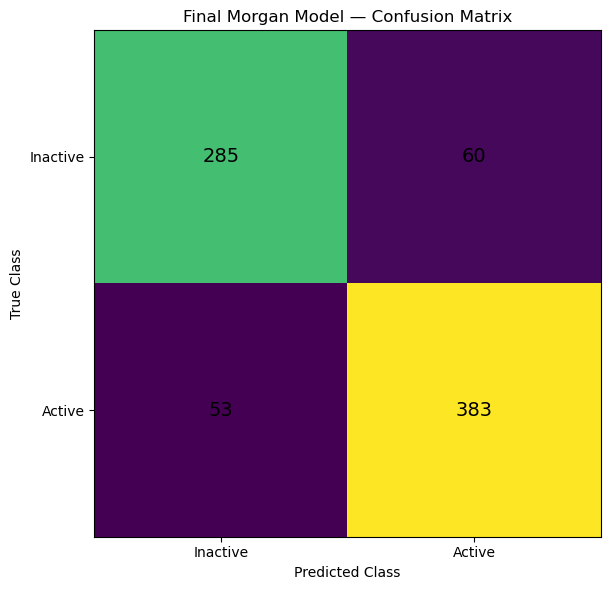


✓ Confusion matrix saved:
  grand_final_selection/final_morgan_confusion_matrix.png


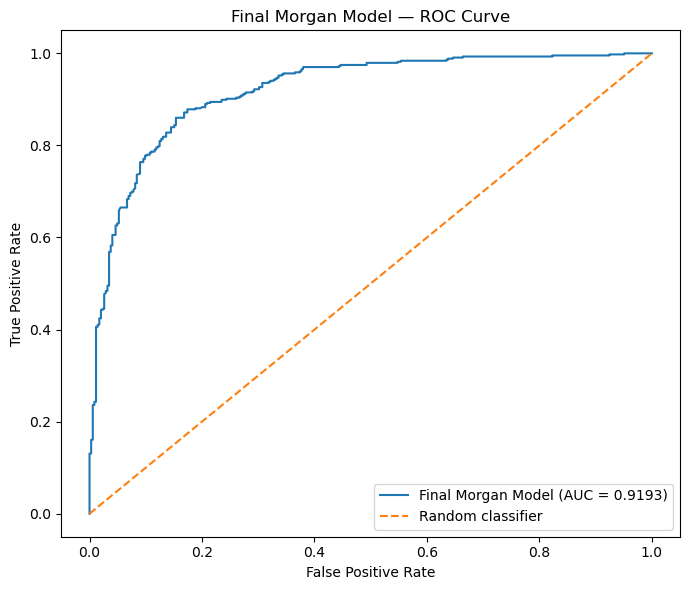


✓ ROC curve saved:
  grand_final_selection/final_morgan_roc_curve.png


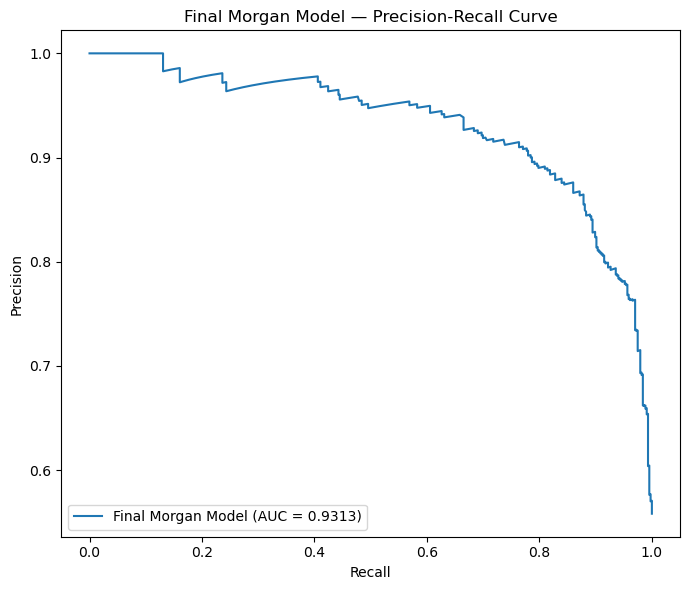


✓ Precision-Recall curve saved:
  grand_final_selection/final_morgan_precision_recall_curve.png

CELL 9 COMPLETED

Final Morgan model:
  ExtraTreesClassifier

Final test ROC-AUC:
  0.9193

Final test F1-score:
  0.8714

Final test MCC:
  0.7061

Saved files:
  ✓ grand_final_selection/final_morgan_model.joblib
  ✓ grand_final_selection/final_morgan_test_metrics.csv
  ✓ grand_final_selection/final_morgan_confusion_matrix.png
  ✓ grand_final_selection/final_morgan_roc_curve.png
  ✓ grand_final_selection/final_morgan_precision_recall_curve.png

IMPORTANT

This is the FINAL evaluation on the locked test set.

The test set must NOT be used again for:
    • Hyperparameter tuning
    • Model selection
    • Feature selection
    • Threshold optimization
    • Soft-voting selection
    • Any further model development

The Morgan model is now finalized.



In [37]:
# ============================================================================
# CELL 9 — FINAL MORGAN MODEL EVALUATION ON LOCKED TEST SET
# ============================================================================
#
# IMPORTANT:
#   This is the FIRST step where X_test and y_test are used.
#
#   The final model was selected automatically from:
#       1. Best tuned individual model
#       2. Top-3 Soft Voting model
#
#   The selected model should already be saved as:
#
#       grand_final_selection/
#           final_morgan_model.joblib
#
#   This cell:
#       1. Automatically loads the final Morgan model
#       2. Evaluates it on X_test / y_test
#       3. Calculates final classification metrics
#       4. Saves the final metrics
#       5. Generates confusion matrix
#       6. Generates ROC curve
#       7. Generates Precision-Recall curve
#
#   TEST SET IS USED ONLY HERE FOR FINAL EVALUATION.
# ============================================================================


# ============================================================================
# 1. IMPORT LIBRARIES
# ============================================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    roc_curve,
    precision_recall_curve,
    auc
)


# ============================================================================
# 2. SETTINGS
# ============================================================================

FINAL_FOLDER = "grand_final_selection"

FINAL_MODEL_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_model.joblib"
)

METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_test_metrics.csv"
)

CONFUSION_MATRIX_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_confusion_matrix.png"
)

ROC_CURVE_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_roc_curve.png"
)

PR_CURVE_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_precision_recall_curve.png"
)


# ============================================================================
# 3. CHECK FINAL MODEL
# ============================================================================

print("\n" + "=" * 100)
print("FINAL MORGAN MODEL — TEST SET EVALUATION")
print("=" * 100)

print("\nFinal model folder:")
print(os.path.abspath(FINAL_FOLDER))

print("\nFinal model file:")
print(FINAL_MODEL_FILE)


if not os.path.exists(FINAL_MODEL_FILE):

    raise FileNotFoundError(
        f"\nFINAL MORGAN MODEL NOT FOUND:\n"
        f"{FINAL_MODEL_FILE}\n\n"
        f"Please run the previous final model selection cell first."
    )


# ============================================================================
# 4. LOAD FINAL MORGAN MODEL
# ============================================================================

final_morgan_model = joblib.load(FINAL_MODEL_FILE)

print("\n✓ Final Morgan model loaded successfully.")

print("\nModel type:")
print(type(final_morgan_model).__name__)


# ============================================================================
# 5. VERIFY TEST SET
# ============================================================================

print("\n" + "=" * 100)
print("LOCKED TEST SET")
print("=" * 100)

print(f"\nTest samples : {len(X_test):,}")
print(f"Test features: {X_test.shape[1]:,}")

print("\nTest class distribution:")
print(y_test.value_counts())


# ============================================================================
# 6. GENERATE TEST PREDICTIONS
# ============================================================================

print("\n" + "=" * 100)
print("GENERATING FINAL TEST PREDICTIONS")
print("=" * 100)

# Predicted class
y_pred = final_morgan_model.predict(X_test)


# ============================================================================
# 7. GENERATE PROBABILITIES / DECISION SCORES
# ============================================================================

# Most classifiers provide predict_proba.
if hasattr(final_morgan_model, "predict_proba"):

    y_prob = final_morgan_model.predict_proba(X_test)[:, 1]

    probability_method = "predict_proba"

elif hasattr(final_morgan_model, "decision_function"):

    y_score = final_morgan_model.decision_function(X_test)

    # Convert decision scores to a 0–1 scale only for models
    # that do not provide probabilities.
    y_prob = (
        (y_score - np.min(y_score)) /
        (np.max(y_score) - np.min(y_score))
        if np.max(y_score) != np.min(y_score)
        else np.zeros_like(y_score)
    )

    probability_method = "decision_function_rescaled"

else:

    raise AttributeError(
        "The final Morgan model does not provide "
        "predict_proba() or decision_function()."
    )


print("\n✓ Predictions generated.")
print(f"Probability/score method: {probability_method}")


# ============================================================================
# 8. CONFUSION MATRIX VALUES
# ============================================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()


# ============================================================================
# 9. CALCULATE FINAL TEST METRICS
# ============================================================================

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

sensitivity = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

mcc = matthews_corrcoef(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


# ============================================================================
# 10. DISPLAY FINAL RESULTS
# ============================================================================

print("\n" + "=" * 100)
print("FINAL MORGAN TEST-SET PERFORMANCE")
print("=" * 100)

print(f"\nROC-AUC              : {roc_auc:.4f}")
print(f"PR-AUC               : {pr_auc:.4f}")
print(f"Accuracy             : {accuracy:.4f}")
print(f"Balanced Accuracy    : {balanced_accuracy:.4f}")
print(f"Precision            : {precision:.4f}")
print(f"Sensitivity (Recall) : {sensitivity:.4f}")
print(f"Specificity          : {specificity:.4f}")
print(f"MCC                  : {mcc:.4f}")
print(f"F1-score             : {f1:.4f}")

print("\n" + "-" * 100)
print("CONFUSION MATRIX")
print("-" * 100)

print(f"\nTrue Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")


# ============================================================================
# 11. SAVE FINAL METRICS
# ============================================================================

final_metrics = pd.DataFrame({
    "Model": ["Final Morgan Model"],
    "Model_Type": [type(final_morgan_model).__name__],
    "ROC_AUC": [roc_auc],
    "PR_AUC": [pr_auc],
    "Accuracy": [accuracy],
    "Balanced_Accuracy": [balanced_accuracy],
    "Precision": [precision],
    "Sensitivity": [sensitivity],
    "Specificity": [specificity],
    "MCC": [mcc],
    "F1_Score": [f1],
    "TN": [tn],
    "FP": [fp],
    "FN": [fn],
    "TP": [tp],
    "Test_Samples": [len(X_test)]
})

final_metrics.to_csv(
    METRICS_FILE,
    index=False
)

print("\n✓ Final metrics saved:")
print(f"  {METRICS_FILE}")


# ============================================================================
# 12. CONFUSION MATRIX PLOT
# ============================================================================

cm = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(cm)

ax.set_title(
    "Final Morgan Model — Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    CONFUSION_MATRIX_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Confusion matrix saved:")
print(f"  {CONFUSION_MATRIX_FILE}")


# ============================================================================
# 13. ROC CURVE
# ============================================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_curve_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Final Morgan Model (AUC = {roc_curve_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Morgan Model — ROC Curve")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    ROC_CURVE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ ROC curve saved:")
print(f"  {ROC_CURVE_FILE}")


# ============================================================================
# 14. PRECISION-RECALL CURVE
# ============================================================================

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

pr_curve_auc = auc(
    recall_values,
    precision_values
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Final Morgan Model (AUC = {pr_curve_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Morgan Model — Precision-Recall Curve")

plt.legend(loc="lower left")

plt.tight_layout()

plt.savefig(
    PR_CURVE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Precision-Recall curve saved:")
print(f"  {PR_CURVE_FILE}")


# ============================================================================
# 15. FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("CELL 9 COMPLETED")
print("=" * 100)

print("\nFinal Morgan model:")
print(f"  {type(final_morgan_model).__name__}")

print("\nFinal test ROC-AUC:")
print(f"  {roc_auc:.4f}")

print("\nFinal test F1-score:")
print(f"  {f1:.4f}")

print("\nFinal test MCC:")
print(f"  {mcc:.4f}")

print("\nSaved files:")
print(f"  ✓ {FINAL_MODEL_FILE}")
print(f"  ✓ {METRICS_FILE}")
print(f"  ✓ {CONFUSION_MATRIX_FILE}")
print(f"  ✓ {ROC_CURVE_FILE}")
print(f"  ✓ {PR_CURVE_FILE}")

print("\n" + "=" * 100)
print("IMPORTANT")
print("=" * 100)

print("""
This is the FINAL evaluation on the locked test set.

The test set must NOT be used again for:
    • Hyperparameter tuning
    • Model selection
    • Feature selection
    • Threshold optimization
    • Soft-voting selection
    • Any further model development

The Morgan model is now finalized.
""")

print("=" * 100)


CELL 10 — FINAL MORGAN PUBLICATION ANALYSIS

Loading final Morgan model...
Final model loaded successfully:
  grand_final_selection/final_morgan_model.joblib

Model type:
  ExtraTreesClassifier

--------------------------------------------------------------------------------
DATASET INFORMATION
--------------------------------------------------------------------------------
Training samples : 3,120
Test samples     : 781
Number of features: 2,048

Training class distribution:
Activity
0    1379
1    1741
Name: count, dtype: int64

Test class distribution:
Activity
0    345
1    436
Name: count, dtype: int64

--------------------------------------------------------------------------------
FINAL TEST-SET PREDICTIONS
--------------------------------------------------------------------------------
Prediction completed in 0.185 seconds.

--------------------------------------------------------------------------------
FINAL TEST METRICS
------------------------------------------------------

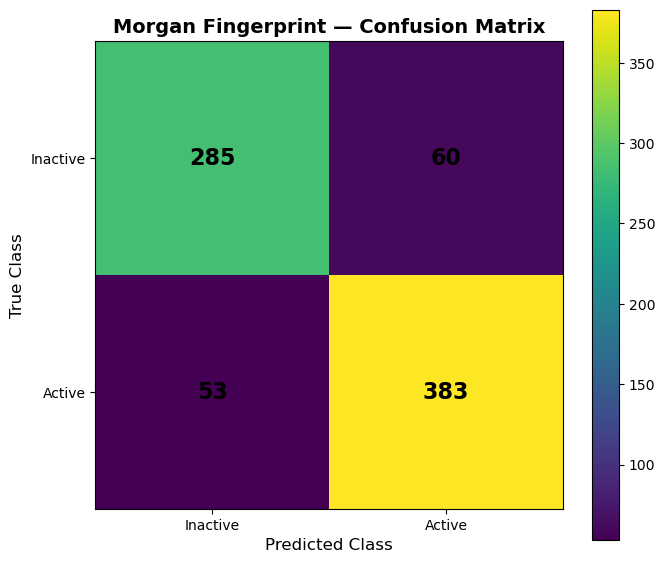

Numbered confusion matrix saved:
grand_final_selection/final_morgan_confusion_matrix_numbered.png

--------------------------------------------------------------------------------
NORMALIZED CONFUSION MATRIX
--------------------------------------------------------------------------------

Normalized confusion matrix:
          Inactive  Active
Inactive    0.8261  0.1739
Active      0.1216  0.8784


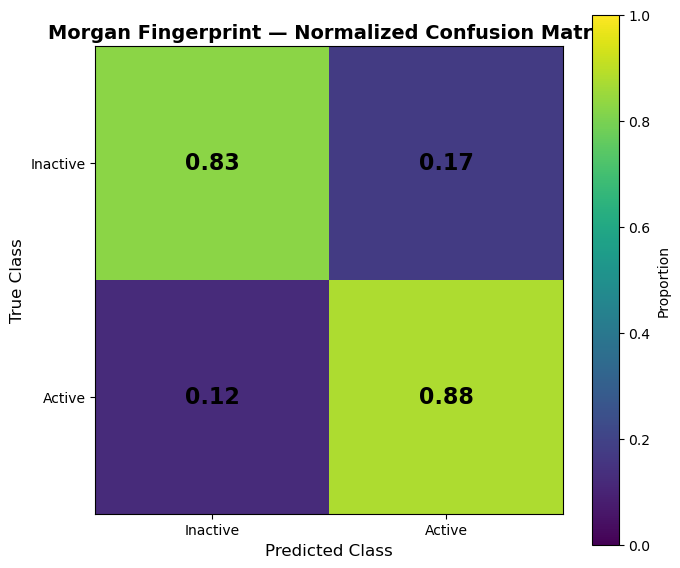

Normalized confusion matrix saved:
grand_final_selection/final_morgan_normalized_confusion_matrix.png

--------------------------------------------------------------------------------
ROC CURVE
--------------------------------------------------------------------------------


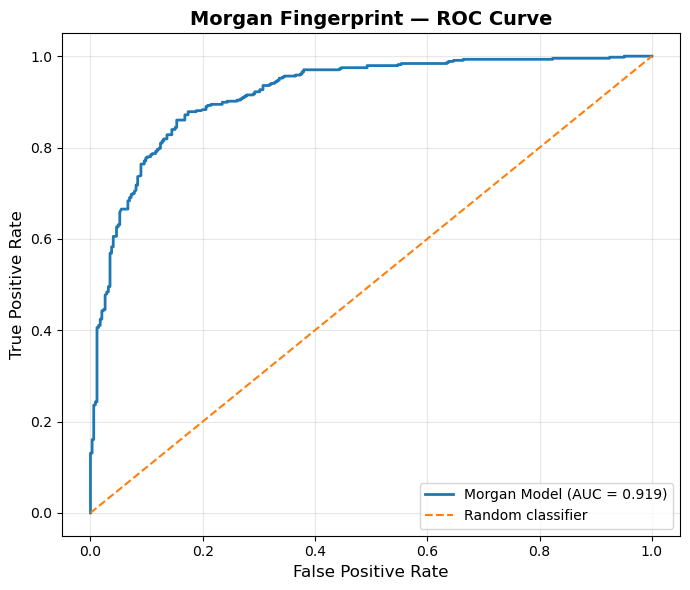

ROC curve saved:
grand_final_selection/final_morgan_roc_curve.png

--------------------------------------------------------------------------------
PRECISION–RECALL CURVE
--------------------------------------------------------------------------------


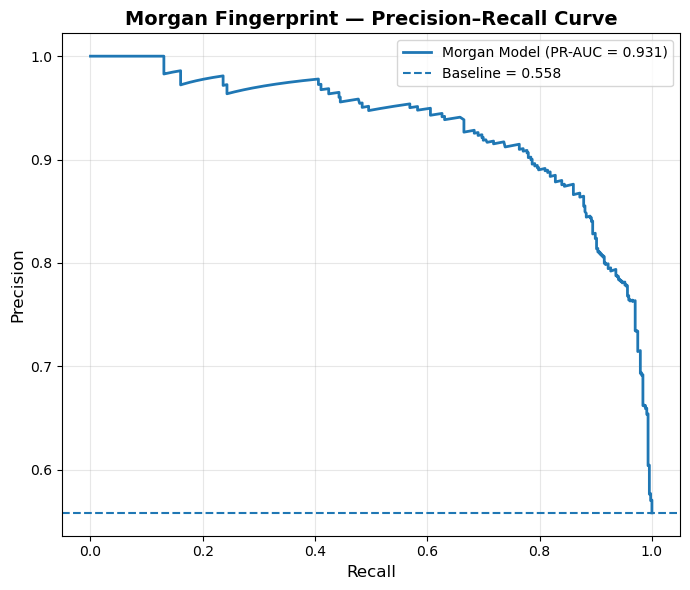

Precision–Recall curve saved:
grand_final_selection/final_morgan_precision_recall_curve.png

Y-SCRAMBLING / Y-RANDOMIZATION TEST

IMPORTANT:
  X_test and y_test are NOT used.
  Only X_train and y_train are used.
  Number of permutations: 100
  CV folds: 5

Calculating true-label CV ROC-AUC...
True-label CV ROC-AUC: 0.9040 ± 0.0133
Completed in 4.07 seconds.
Scramble   1/100 | ROC-AUC = 0.5124 | Elapsed = 5.5s
Scramble  10/100 | ROC-AUC = 0.5013 | Elapsed = 51.2s
Scramble  20/100 | ROC-AUC = 0.4999 | Elapsed = 102.1s
Scramble  30/100 | ROC-AUC = 0.5038 | Elapsed = 153.9s
Scramble  40/100 | ROC-AUC = 0.4605 | Elapsed = 206.4s
Scramble  50/100 | ROC-AUC = 0.5254 | Elapsed = 259.5s
Scramble  60/100 | ROC-AUC = 0.5049 | Elapsed = 312.5s
Scramble  70/100 | ROC-AUC = 0.4921 | Elapsed = 364.5s
Scramble  80/100 | ROC-AUC = 0.5088 | Elapsed = 417.2s
Scramble  90/100 | ROC-AUC = 0.5060 | Elapsed = 468.4s
Scramble 100/100 | ROC-AUC = 0.5004 | Elapsed = 518.3s

Y-scrambling results saved:
grand_fin

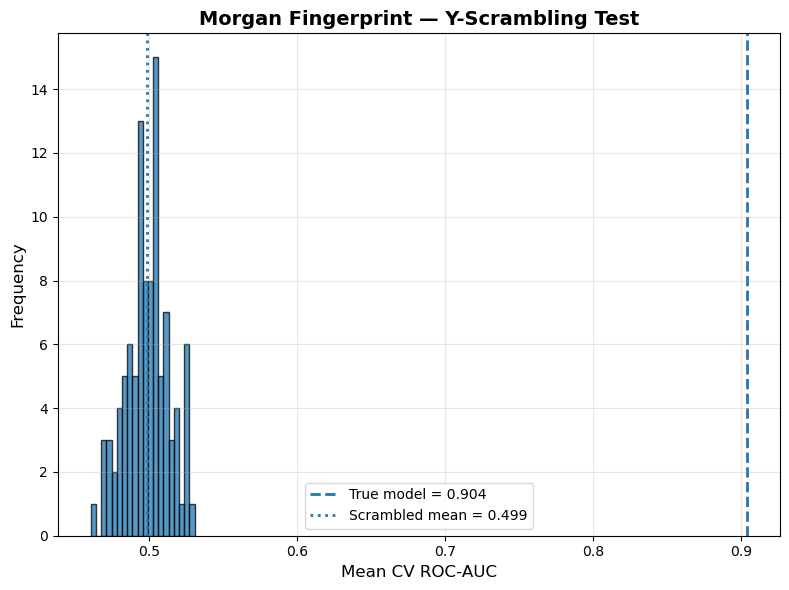

Y-scrambling figure saved:
grand_final_selection/final_morgan_y_scrambling_distribution.png

--------------------------------------------------------------------------------
PREDICTION PROBABILITY DISTRIBUTION
--------------------------------------------------------------------------------


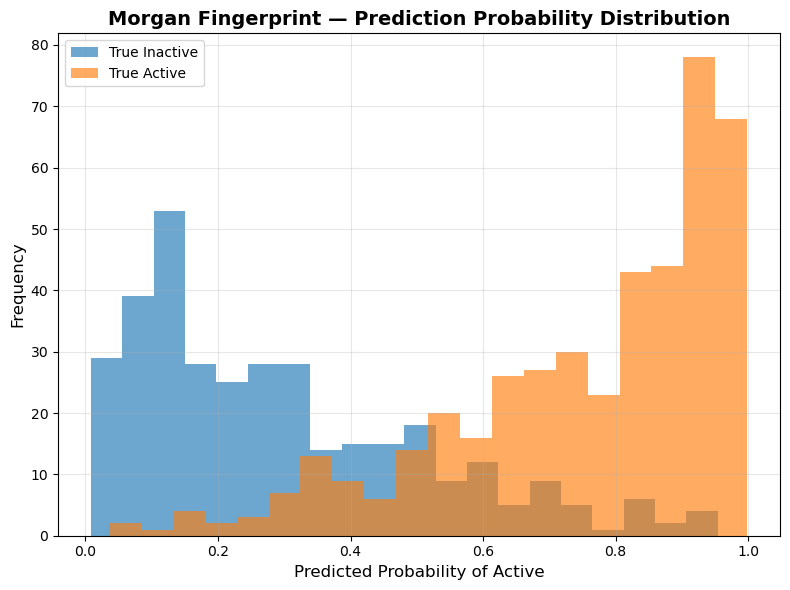

Probability distribution saved:
grand_final_selection/final_morgan_prediction_probability_distribution.png

--------------------------------------------------------------------------------
CALIBRATION CURVE
--------------------------------------------------------------------------------


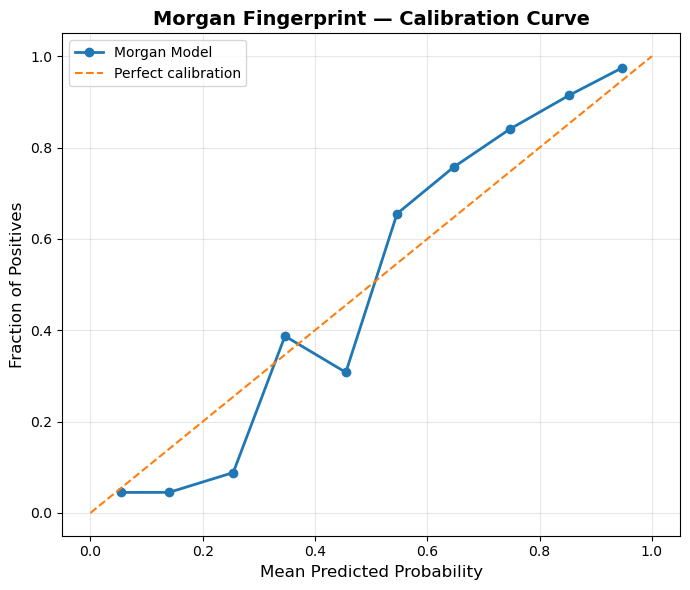

Calibration curve saved:
grand_final_selection/final_morgan_calibration_curve.png

--------------------------------------------------------------------------------
CUMULATIVE GAIN CURVE
--------------------------------------------------------------------------------


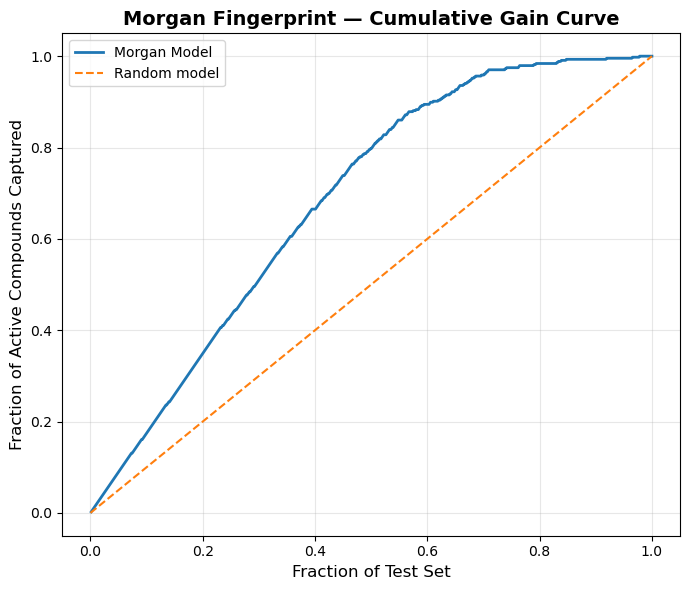

Cumulative gain curve saved:
grand_final_selection/final_morgan_cumulative_gain.png

--------------------------------------------------------------------------------
FINAL METRIC SUMMARY
--------------------------------------------------------------------------------


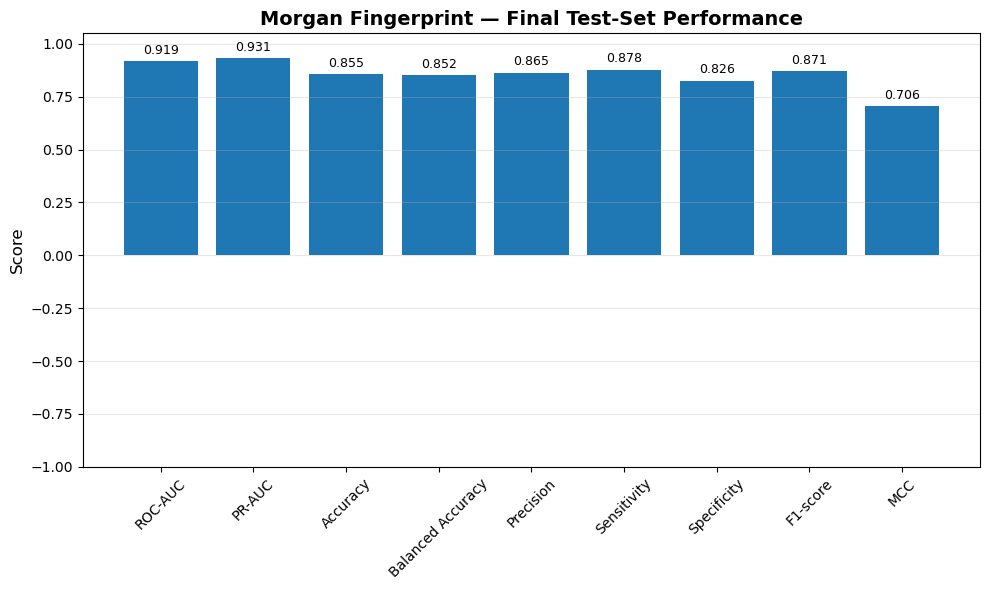

Metric summary figure saved:
grand_final_selection/final_morgan_metric_summary.png

Complete publication analysis saved:
grand_final_selection/final_morgan_complete_publication_analysis.csv
Test metrics saved:
grand_final_selection/final_morgan_test_metrics.csv

--------------------------------------------------------------------------------
CREATING MASTER PUBLICATION FIGURE
--------------------------------------------------------------------------------


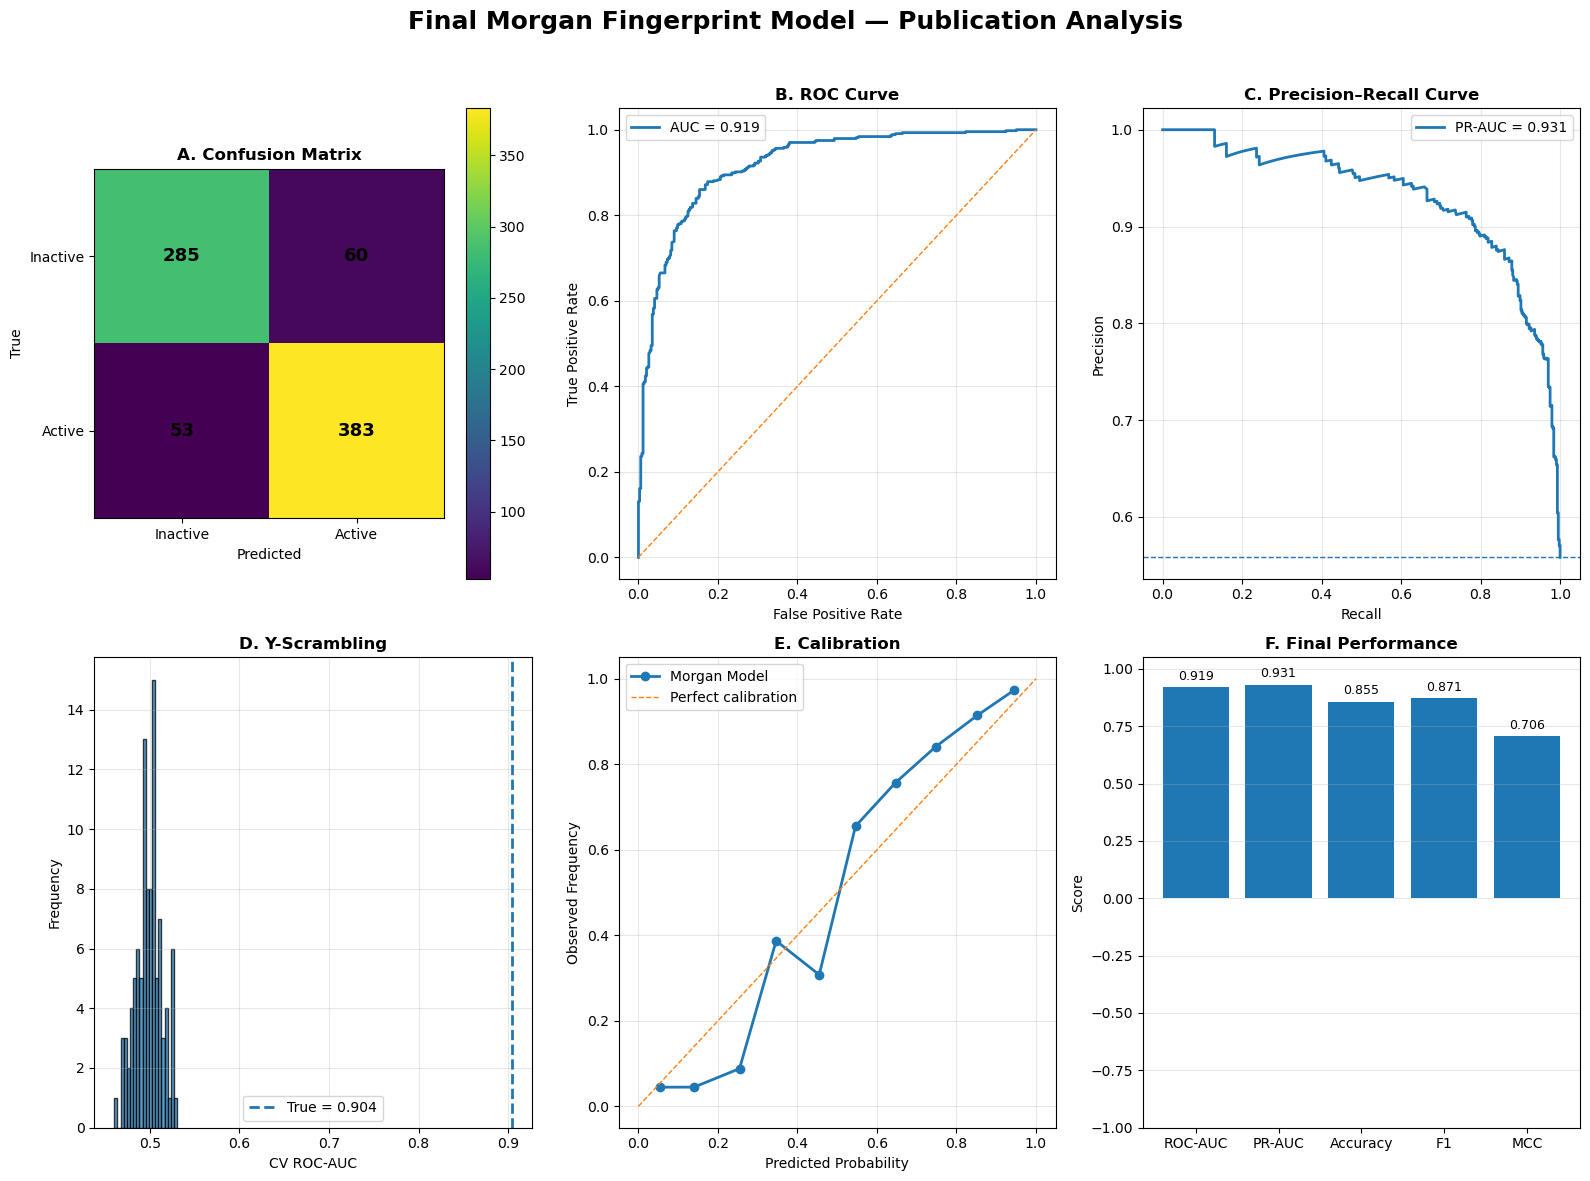

Master publication figure saved:
grand_final_selection/final_morgan_master_publication_figure.png

CELL 10 COMPLETED SUCCESSFULLY

FINAL TEST PERFORMANCE
--------------------------------------------------------------------------------
ROC-AUC               : 0.9193
PR-AUC                : 0.9314
Accuracy              : 0.8553
Balanced Accuracy     : 0.8523
Precision             : 0.8646
Sensitivity           : 0.8784
Specificity           : 0.8261
F1-score              : 0.8714
MCC                   : 0.7061
Overall Score         : 0.8492

Y-SCRAMBLING
--------------------------------------------------------------------------------
True CV ROC-AUC       : 0.9040 ± 0.0133
Scrambled mean        : 0.4986 ± 0.0148
Y-scrambling Z-score  : 27.4177
Empirical p-value     : 1.0000
Number of scrambles   : 100

FILES CREATED IN grand_final_selection/
✓ final_morgan_model.joblib                               72.43 MB
✓ final_morgan_test_metrics.csv                           0.00 MB
✓ final_morgan_

In [39]:
# ============================================================================
# CELL 10 — FINAL MORGAN MODEL: PUBLICATION-READY ANALYSIS
# ============================================================================
#
# PURPOSE
# -------
# This cell performs the final publication-oriented analysis of the already
# selected Morgan fingerprint model.
#
# IMPORTANT METHODOLOGICAL RULE
# -----------------------------
# The test set (X_test, y_test) is used ONLY for final descriptive evaluation.
# It must NOT be used for model selection or hyperparameter tuning.
#
# Y-SCRAMBLING / Y-RANDOMIZATION
# ------------------------------
# Y-scrambling is performed ONLY on the training set:
#
#       X_train + shuffled y_train
#
# The untouched test set is NEVER used during Y-scrambling.
#
# ALL OUTPUTS ARE SAVED DIRECTLY INTO:
#
#       grand_final_selection/
#
# No additional subfolders are created.
#
# ============================================================================


# ============================================================================
# 1. IMPORT LIBRARIES

# ============================================================================

# ============================================================================
# CELL 10 — FINAL MORGAN MODEL: PUBLICATION-READY ANALYSIS
# ============================================================================

# ============================================================================
# 1. IMPORT LIBRARIES
# ============================================================================

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    f1_score,
    matthews_corrcoef
)

from sklearn.calibration import calibration_curve

import joblib

warnings.filterwarnings("ignore")


# ============================================================================
# 2. SETTINGS
# ============================================================================

RANDOM_STATE = 57

N_SCRAMBLES = 100

CV_FOLDS = 5

POSITIVE_CLASS = "Active"
NEGATIVE_CLASS = "Inactive"

FINAL_FOLDER = "grand_final_selection"

os.makedirs(
    FINAL_FOLDER,
    exist_ok=True
)




# 3. FILE PATHS
# ============================================================================

FINAL_MODEL_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_model.joblib"
)

TEST_METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_test_metrics.csv"
)

PUBLICATION_METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_publication_metrics.csv"
)

COMPLETE_ANALYSIS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_complete_publication_analysis.csv"
)

CONFUSION_NUMBERS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_confusion_matrix_numbers.csv"
)

CONFUSION_NORMALIZED_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_normalized_confusion_matrix.csv"
)

Y_SCRAMBLING_RESULTS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_y_scrambling_results.csv"
)

Y_SCRAMBLING_SUMMARY_FILE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_y_scrambling_summary.csv"
)


# ============================================================================
# FIGURE PATHS
# ============================================================================

CONFUSION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_confusion_matrix_numbered.png"
)

NORMALIZED_CONFUSION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_normalized_confusion_matrix.png"
)

ROC_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_roc_curve.png"
)

PR_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_precision_recall_curve.png"
)

Y_SCRAMBLING_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_y_scrambling_distribution.png"
)

PROBABILITY_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_prediction_probability_distribution.png"
)

CALIBRATION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_calibration_curve.png"
)

GAIN_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_cumulative_gain.png"
)

METRIC_SUMMARY_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_metric_summary.png"
)

MASTER_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_morgan_master_publication_figure.png"
)


# ============================================================================
# 4. CHECK REQUIRED VARIABLES
# ============================================================================

required_variables = [
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing:\n"
        + ", ".join(missing_variables)
        + "\n\nPlease run the previous cells first."
    )


# ============================================================================
# 5. LOAD FINAL MODEL
# ============================================================================

print("\n" + "=" * 80)
print("CELL 10 — FINAL MORGAN PUBLICATION ANALYSIS")
print("=" * 80)

print("\nLoading final Morgan model...")

if not os.path.exists(FINAL_MODEL_FILE):
    raise FileNotFoundError(
        f"Final model not found:\n{FINAL_MODEL_FILE}"
    )

import joblib

final_model = joblib.load(FINAL_MODEL_FILE)

print(f"Final model loaded successfully:")
print(f"  {FINAL_MODEL_FILE}")

print("\nModel type:")
print(f"  {type(final_model).__name__}")


# ============================================================================
# 6. BASIC DATASET INFORMATION
# ============================================================================

print("\n" + "-" * 80)
print("DATASET INFORMATION")
print("-" * 80)

print(f"Training samples : {len(X_train):,}")
print(f"Test samples     : {len(X_test):,}")

print(f"Number of features: {X_train.shape[1]:,}")

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


# ============================================================================
# 7. FINAL TEST-SET PREDICTIONS
# ============================================================================

print("\n" + "-" * 80)
print("FINAL TEST-SET PREDICTIONS")
print("-" * 80)

start_time = time.time()

# Class predictions
y_test_pred = final_model.predict(X_test)

# Probability predictions
if hasattr(final_model, "predict_proba"):

    y_test_proba = final_model.predict_proba(X_test)

    # Determine positive-class column
    if hasattr(final_model, "classes_"):
        classes = list(final_model.classes_)

        if 1 in classes:
            positive_index = classes.index(1)
        else:
            positive_index = 1

        y_test_probability = y_test_proba[:, positive_index]

    else:
        y_test_probability = y_test_proba[:, 1]

elif hasattr(final_model, "decision_function"):

    decision_scores = final_model.decision_function(X_test)

    # Convert decision scores to approximately 0–1 probabilities
    y_test_probability = (
        1 / (1 + np.exp(-decision_scores))
    )

else:

    raise AttributeError(
        "The final model does not provide predict_proba "
        "or decision_function."
    )

prediction_time = time.time() - start_time

print(f"Prediction completed in {prediction_time:.3f} seconds.")


# ============================================================================
# 8. CONVERT LABELS TO NUMERIC FORMAT IF NECESSARY
# ============================================================================

def convert_labels_to_binary(y):
    """
    Convert Active/Inactive or 1/0 labels into binary 1/0.
    """

    y_series = pd.Series(y)

    if y_series.dtype == object:

        mapping = {
            POSITIVE_CLASS: 1,
            NEGATIVE_CLASS: 0,
            "Active": 1,
            "Inactive": 0,
            "active": 1,
            "inactive": 0
        }

        y_binary = y_series.map(mapping)

        if y_binary.isna().any():

            unique_values = y_series.unique()

            raise ValueError(
                "Unable to convert labels to binary format.\n"
                f"Unique labels found: {unique_values}"
            )

        return y_binary.astype(int).values

    return y_series.astype(int).values


y_test_binary = convert_labels_to_binary(y_test)
y_pred_binary = convert_labels_to_binary(y_test_pred)


# ============================================================================
# 9. CALCULATE FINAL TEST METRICS
# ============================================================================

print("\n" + "-" * 80)
print("FINAL TEST METRICS")
print("-" * 80)

# ROC-AUC
test_roc_auc = roc_auc_score(
    y_test_binary,
    y_test_probability
)

# PR-AUC
test_pr_auc = average_precision_score(
    y_test_binary,
    y_test_probability
)

# Accuracy
test_accuracy = accuracy_score(
    y_test_binary,
    y_pred_binary
)

# Balanced accuracy
test_balanced_accuracy = balanced_accuracy_score(
    y_test_binary,
    y_pred_binary
)

# Precision
test_precision = precision_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# Sensitivity / Recall
test_sensitivity = recall_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# Specificity
tn, fp, fn, tp = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1]
).ravel()

if (tn + fp) > 0:
    test_specificity = tn / (tn + fp)
else:
    test_specificity = np.nan

# F1
test_f1 = f1_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# MCC
test_mcc = matthews_corrcoef(
    y_test_binary,
    y_pred_binary
)

# Overall score
test_overall_score = np.mean([
    test_roc_auc,
    test_f1,
    test_mcc,
    test_accuracy,
    test_precision,
    test_sensitivity
])

test_metrics = {
    "ROC-AUC": test_roc_auc,
    "PR-AUC": test_pr_auc,
    "Accuracy": test_accuracy,
    "Balanced Accuracy": test_balanced_accuracy,
    "Precision": test_precision,
    "Sensitivity": test_sensitivity,
    "Specificity": test_specificity,
    "F1-score": test_f1,
    "MCC": test_mcc,
    "Overall Score": test_overall_score
}

for metric, value in test_metrics.items():
    print(f"{metric:20s}: {value:.4f}")


# ============================================================================
# 10. SAVE PUBLICATION METRICS
# ============================================================================

publication_metrics_df = pd.DataFrame({
    "Metric": list(test_metrics.keys()),
    "Value": list(test_metrics.values())
})

publication_metrics_df.to_csv(
    PUBLICATION_METRICS_FILE,
    index=False
)

print(
    f"\nPublication metrics saved:\n"
    f"{PUBLICATION_METRICS_FILE}"
)


# ============================================================================
# 11. CONFUSION MATRIX — NUMBERED
# ============================================================================

print("\n" + "-" * 80)
print("CONFUSION MATRIX — NUMBERED")
print("-" * 80)

cm = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=[NEGATIVE_CLASS, POSITIVE_CLASS],
    columns=[NEGATIVE_CLASS, POSITIVE_CLASS]
)

cm_df.to_csv(
    CONFUSION_NUMBERS_FILE
)

print("\nConfusion matrix:")
print(cm_df)


# ============================================================================
# 12. PLOT NUMBERED CONFUSION MATRIX
# ============================================================================

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation="nearest")

ax.set_title(
    "Morgan Fingerprint — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12
)

ax.set_ylabel(
    "True Class",
    fontsize=12
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

# Add numbers
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

# Add colorbar
fig.colorbar(im, ax=ax)

plt.tight_layout()

plt.savefig(
    CONFUSION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Numbered confusion matrix saved:\n"
    f"{CONFUSION_FIGURE}"
)


# ============================================================================
# 13. NORMALIZED CONFUSION MATRIX
# ============================================================================

print("\n" + "-" * 80)
print("NORMALIZED CONFUSION MATRIX")
print("-" * 80)

cm_normalized = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1],
    normalize="true"
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=[NEGATIVE_CLASS, POSITIVE_CLASS],
    columns=[NEGATIVE_CLASS, POSITIVE_CLASS]
)

cm_normalized_df.to_csv(
    CONFUSION_NORMALIZED_FILE
)

print("\nNormalized confusion matrix:")
print(cm_normalized_df.round(4))


# ============================================================================
# 14. PLOT NORMALIZED CONFUSION MATRIX
# ============================================================================

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    vmin=0,
    vmax=1
)

ax.set_title(
    "Morgan Fingerprint — Normalized Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12
)

ax.set_ylabel(
    "True Class",
    fontsize=12
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Proportion"
)

plt.tight_layout()

plt.savefig(
    NORMALIZED_CONFUSION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Normalized confusion matrix saved:\n"
    f"{NORMALIZED_CONFUSION_FIGURE}"
)


# ============================================================================
# 15. ROC CURVE
# ============================================================================

print("\n" + "-" * 80)
print("ROC CURVE")
print("-" * 80)

fpr, tpr, roc_thresholds = roc_curve(
    y_test_binary,
    y_test_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Morgan Model (AUC = {test_roc_auc:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=12
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — ROC Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend(
    loc="lower right"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ROC_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(f"ROC curve saved:\n{ROC_FIGURE}")


# ============================================================================
# 16. PRECISION–RECALL CURVE
# ============================================================================

print("\n" + "-" * 80)
print("PRECISION–RECALL CURVE")
print("-" * 80)

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test_binary,
    y_test_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"Morgan Model (PR-AUC = {test_pr_auc:.3f})"
)

baseline = np.mean(y_test_binary)

ax.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline = {baseline:.3f}"
)

ax.set_xlabel(
    "Recall",
    fontsize=12
)

ax.set_ylabel(
    "Precision",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Precision–Recall Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend(
    loc="best"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PR_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Precision–Recall curve saved:\n"
    f"{PR_FIGURE}"
)


# ============================================================================
# 17. Y-SCRAMBLING / Y-RANDOMIZATION TEST
# ============================================================================
#
# IMPORTANT:
#
# The final test set is NOT used here.
#
# Only:
#
#       X_train
#       y_train
#
# are used.
#
# The final model architecture and hyperparameters remain unchanged.
#
# Only the labels are randomly shuffled.
#
# ============================================================================

print("\n" + "=" * 80)
print("Y-SCRAMBLING / Y-RANDOMIZATION TEST")
print("=" * 80)

print("\nIMPORTANT:")
print("  X_test and y_test are NOT used.")
print("  Only X_train and y_train are used.")
print(f"  Number of permutations: {N_SCRAMBLES}")
print(f"  CV folds: {CV_FOLDS}")


# ============================================================================
# 18. TRUE-LABEL CROSS-VALIDATION ROC-AUC
# ============================================================================

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\nCalculating true-label CV ROC-AUC...")

start_time = time.time()

true_cv_scores = cross_val_score(
    clone(final_model),
    X_train,
    convert_labels_to_binary(y_train),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

true_cv_mean = np.mean(true_cv_scores)
true_cv_std = np.std(true_cv_scores)

print(
    f"True-label CV ROC-AUC: "
    f"{true_cv_mean:.4f} ± {true_cv_std:.4f}"
)

print(
    f"Completed in "
    f"{time.time() - start_time:.2f} seconds."
)


# ============================================================================
# 19. Y-SCRAMBLING LOOP
# ============================================================================

X_train_for_scrambling = X_train

y_train_binary = convert_labels_to_binary(y_train)

scrambled_results = []

rng = np.random.RandomState(
    RANDOM_STATE
)

scrambling_start = time.time()

for i in range(1, N_SCRAMBLES + 1):

    # ------------------------------------------------------------
    # Shuffle labels
    # ------------------------------------------------------------

    y_scrambled = rng.permutation(
        y_train_binary
    )

    # ------------------------------------------------------------
    # Create fresh copy of model
    # ------------------------------------------------------------

    scrambled_model = clone(
        final_model
    )

    # ------------------------------------------------------------
    # Cross-validation on scrambled labels
    # ------------------------------------------------------------

    scrambled_scores = cross_val_score(
        scrambled_model,
        X_train_for_scrambling,
        y_scrambled,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    scrambled_mean = np.mean(
        scrambled_scores
    )

    scrambled_std = np.std(
        scrambled_scores
    )

    scrambled_results.append({
        "Scramble": i,
        "Mean_CV_ROC_AUC": scrambled_mean,
        "SD_CV_ROC_AUC": scrambled_std,
        "Difference_From_True": (
            true_cv_mean - scrambled_mean
        )
    })

    # ------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------

    if (
        i == 1
        or i % 10 == 0
        or i == N_SCRAMBLES
    ):

        elapsed = time.time() - scrambling_start

        print(
            f"Scramble {i:3d}/{N_SCRAMBLES} | "
            f"ROC-AUC = {scrambled_mean:.4f} | "
            f"Elapsed = {elapsed:.1f}s"
        )


# ============================================================================
# 20. Y-SCRAMBLING RESULTS DATAFRAME
# ============================================================================

y_scrambling_df = pd.DataFrame(
    scrambled_results
)

y_scrambling_df.to_csv(
    Y_SCRAMBLING_RESULTS_FILE,
    index=False
)

print(
    f"\nY-scrambling results saved:\n"
    f"{Y_SCRAMBLING_RESULTS_FILE}"
)


# ============================================================================
# 21. Y-SCRAMBLING SUMMARY
# ============================================================================

scrambled_mean = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].mean()

scrambled_std = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].std()

scrambled_min = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].min()

scrambled_max = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].max()

# Compare true model against scrambled models
number_scrambled_below_true = np.sum(
    y_scrambling_df["Mean_CV_ROC_AUC"]
    < true_cv_mean
)

empirical_p_value = (
    number_scrambled_below_true + 1
) / (
    N_SCRAMBLES + 1
)

# Z-score
if scrambled_std > 0:

    y_scrambling_z_score = (
        true_cv_mean - scrambled_mean
    ) / scrambled_std

else:

    y_scrambling_z_score = np.nan


y_scrambling_summary = pd.DataFrame({
    "Parameter": [
        "True_CV_ROC_AUC",
        "True_CV_ROC_AUC_SD",
        "Scrambled_Mean_ROC_AUC",
        "Scrambled_SD_ROC_AUC",
        "Scrambled_Min_ROC_AUC",
        "Scrambled_Max_ROC_AUC",
        "Y_Scrambling_Z_Score",
        "Empirical_P_Value",
        "Number_of_Scrambles",
        "CV_Folds"
    ],
    "Value": [
        true_cv_mean,
        true_cv_std,
        scrambled_mean,
        scrambled_std,
        scrambled_min,
        scrambled_max,
        y_scrambling_z_score,
        empirical_p_value,
        N_SCRAMBLES,
        CV_FOLDS
    ]
})

y_scrambling_summary.to_csv(
    Y_SCRAMBLING_SUMMARY_FILE,
    index=False
)

print("\nY-scrambling summary:")
print(
    y_scrambling_summary.to_string(
        index=False
    )
)


# ============================================================================
# 22. Y-SCRAMBLING DISTRIBUTION FIGURE
# ============================================================================

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(
    y_scrambling_df["Mean_CV_ROC_AUC"],
    bins=20,
    alpha=0.75,
    edgecolor="black"
)

ax.axvline(
    true_cv_mean,
    linestyle="--",
    linewidth=2,
    label=f"True model = {true_cv_mean:.3f}"
)

ax.axvline(
    scrambled_mean,
    linestyle=":",
    linewidth=2,
    label=f"Scrambled mean = {scrambled_mean:.3f}"
)

ax.set_xlabel(
    "Mean CV ROC-AUC",
    fontsize=12
)

ax.set_ylabel(
    "Frequency",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Y-Scrambling Test",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    Y_SCRAMBLING_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Y-scrambling figure saved:\n"
    f"{Y_SCRAMBLING_FIGURE}"
)


# ============================================================================
# 23. PREDICTION PROBABILITY DISTRIBUTION
# ============================================================================

print("\n" + "-" * 80)
print("PREDICTION PROBABILITY DISTRIBUTION")
print("-" * 80)

active_probabilities = y_test_probability[
    y_test_binary == 1
]

inactive_probabilities = y_test_probability[
    y_test_binary == 0
]

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(
    inactive_probabilities,
    bins=20,
    alpha=0.65,
    label="True Inactive"
)

ax.hist(
    active_probabilities,
    bins=20,
    alpha=0.65,
    label="True Active"
)

ax.set_xlabel(
    "Predicted Probability of Active",
    fontsize=12
)

ax.set_ylabel(
    "Frequency",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Prediction Probability Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PROBABILITY_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Probability distribution saved:\n"
    f"{PROBABILITY_FIGURE}"
)


# ============================================================================
# 24. CALIBRATION CURVE
# ============================================================================

print("\n" + "-" * 80)
print("CALIBRATION CURVE")
print("-" * 80)

prob_true, prob_pred = calibration_curve(
    y_test_binary,
    y_test_probability,
    n_bins=10,
    strategy="uniform"
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Morgan Model"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

ax.set_xlabel(
    "Mean Predicted Probability",
    fontsize=12
)

ax.set_ylabel(
    "Fraction of Positives",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Calibration Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    CALIBRATION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Calibration curve saved:\n"
    f"{CALIBRATION_FIGURE}"
)


# ============================================================================
# 25. CUMULATIVE GAIN CURVE
# ============================================================================

print("\n" + "-" * 80)
print("CUMULATIVE GAIN CURVE")
print("-" * 80)

# Sort by predicted probability
sorted_indices = np.argsort(
    -y_test_probability
)

sorted_labels = y_test_binary[
    sorted_indices
]

total_positives = np.sum(
    y_test_binary
)

if total_positives > 0:

    cumulative_positives = np.cumsum(
        sorted_labels
    )

    cumulative_gain = (
        cumulative_positives /
        total_positives
    )

else:

    cumulative_gain = np.zeros(
        len(sorted_labels)
    )

population_fraction = (
    np.arange(1, len(sorted_labels) + 1)
    / len(sorted_labels)
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    population_fraction,
    cumulative_gain,
    linewidth=2,
    label="Morgan Model"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random model"
)

ax.set_xlabel(
    "Fraction of Test Set",
    fontsize=12
)

ax.set_ylabel(
    "Fraction of Active Compounds Captured",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Cumulative Gain Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    GAIN_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Cumulative gain curve saved:\n"
    f"{GAIN_FIGURE}"
)


# ============================================================================
# 26. FINAL METRIC SUMMARY FIGURE
# ============================================================================

print("\n" + "-" * 80)
print("FINAL METRIC SUMMARY")
print("-" * 80)

metric_names = [
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-score",
    "MCC"
]

metric_values = [
    test_roc_auc,
    test_pr_auc,
    test_accuracy,
    test_balanced_accuracy,
    test_precision,
    test_sensitivity,
    test_specificity,
    test_f1,
    test_mcc
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    metric_names,
    metric_values
)

ax.set_ylim(
    min(-1, min(metric_values) - 0.05),
    1.05
)

ax.set_ylabel(
    "Score",
    fontsize=12
)

ax.set_title(
    "Morgan Fingerprint — Final Test-Set Performance",
    fontsize=14,
    fontweight="bold"
)

ax.tick_params(
    axis="x",
    rotation=45
)

# Numerical values above bars
for bar, value in zip(
    bars,
    metric_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    METRIC_SUMMARY_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Metric summary figure saved:\n"
    f"{METRIC_SUMMARY_FIGURE}"
)


# ============================================================================
# 27. COMPLETE PUBLICATION ANALYSIS TABLE
# ============================================================================

complete_analysis = {
    "Model": [
        "Final Morgan Model"
    ],
    "Fingerprint": [
        "Morgan"
    ],
    "Radius": [
        3
    ],
    "Bits": [
        2048
    ],
    "Test_Samples": [
        len(X_test)
    ],
    "Features": [
        X_test.shape[1]
    ],
    "ROC_AUC": [
        test_roc_auc
    ],
    "PR_AUC": [
        test_pr_auc
    ],
    "Accuracy": [
        test_accuracy
    ],
    "Balanced_Accuracy": [
        test_balanced_accuracy
    ],
    "Precision": [
        test_precision
    ],
    "Sensitivity": [
        test_sensitivity
    ],
    "Specificity": [
        test_specificity
    ],
    "F1_Score": [
        test_f1
    ],
    "MCC": [
        test_mcc
    ],
    "Overall_Score": [
        test_overall_score
    ],
    "True_CV_ROC_AUC": [
        true_cv_mean
    ],
    "True_CV_ROC_AUC_SD": [
        true_cv_std
    ],
    "Y_Scrambled_Mean_ROC_AUC": [
        scrambled_mean
    ],
    "Y_Scrambled_SD": [
        scrambled_std
    ],
    "Y_Scrambling_Z_Score": [
        y_scrambling_z_score
    ],
    "Y_Scrambling_Empirical_P": [
        empirical_p_value
    ],
    "Number_of_Y_Scrambles": [
        N_SCRAMBLES
    ]
}

complete_analysis_df = pd.DataFrame(
    complete_analysis
)

complete_analysis_df.to_csv(
    COMPLETE_ANALYSIS_FILE,
    index=False
)

print(
    f"\nComplete publication analysis saved:\n"
    f"{COMPLETE_ANALYSIS_FILE}"
)


# ============================================================================
# 28. SAVE ORIGINAL TEST METRICS IF NOT ALREADY SAVED
# ============================================================================

test_metrics_df = pd.DataFrame(
    [test_metrics]
)

test_metrics_df.to_csv(
    TEST_METRICS_FILE,
    index=False
)

print(
    f"Test metrics saved:\n"
    f"{TEST_METRICS_FILE}"
)


# ============================================================================
# 29. MASTER PUBLICATION FIGURE
# ============================================================================
#
# This creates ONE convenient figure containing the most important final
# analyses.
#
# Individual high-resolution figures have already been saved separately.
#
# ============================================================================

print("\n" + "-" * 80)
print("CREATING MASTER PUBLICATION FIGURE")
print("-" * 80)

fig = plt.figure(
    figsize=(16, 12)
)

# --------------------------------------------------------------------------
# Panel A — Confusion Matrix
# --------------------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

im1 = ax1.imshow(
    cm,
    interpolation="nearest"
)

ax1.set_title(
    "A. Confusion Matrix",
    fontweight="bold"
)

ax1.set_xlabel(
    "Predicted"
)

ax1.set_ylabel(
    "True"
)

ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])

ax1.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax1.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

for i in range(2):
    for j in range(2):

        ax1.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold"
        )

fig.colorbar(
    im1,
    ax=ax1
)


# --------------------------------------------------------------------------
# Panel B — ROC
# --------------------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {test_roc_auc:.3f}"
)

ax2.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

ax2.set_title(
    "B. ROC Curve",
    fontweight="bold"
)

ax2.set_xlabel(
    "False Positive Rate"
)

ax2.set_ylabel(
    "True Positive Rate"
)

ax2.legend()

ax2.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel C — Precision–Recall
# --------------------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"PR-AUC = {test_pr_auc:.3f}"
)

ax3.axhline(
    baseline,
    linestyle="--",
    linewidth=1
)

ax3.set_title(
    "C. Precision–Recall Curve",
    fontweight="bold"
)

ax3.set_xlabel(
    "Recall"
)

ax3.set_ylabel(
    "Precision"
)

ax3.legend()

ax3.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel D — Y-Scrambling
# --------------------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

ax4.hist(
    y_scrambling_df["Mean_CV_ROC_AUC"],
    bins=20,
    alpha=0.75,
    edgecolor="black"
)

ax4.axvline(
    true_cv_mean,
    linestyle="--",
    linewidth=2,
    label=f"True = {true_cv_mean:.3f}"
)

ax4.set_title(
    "D. Y-Scrambling",
    fontweight="bold"
)

ax4.set_xlabel(
    "CV ROC-AUC"
)

ax4.set_ylabel(
    "Frequency"
)

ax4.legend()

ax4.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel E — Calibration
# --------------------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

ax5.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Morgan Model"
)

ax5.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Perfect calibration"
)

ax5.set_title(
    "E. Calibration",
    fontweight="bold"
)

ax5.set_xlabel(
    "Predicted Probability"
)

ax5.set_ylabel(
    "Observed Frequency"
)

ax5.legend()

ax5.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel F — Final Metrics
# --------------------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6)

short_metric_names = [
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "F1",
    "MCC"
]

short_metric_values = [
    test_roc_auc,
    test_pr_auc,
    test_accuracy,
    test_f1,
    test_mcc
]

bars = ax6.bar(
    short_metric_names,
    short_metric_values
)

ax6.set_ylim(
    min(-1, min(short_metric_values) - 0.05),
    1.05
)

ax6.set_title(
    "F. Final Performance",
    fontweight="bold"
)

ax6.set_ylabel(
    "Score"
)

for bar, value in zip(
    bars,
    short_metric_values
):

    ax6.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax6.grid(
    axis="y",
    alpha=0.3
)


# --------------------------------------------------------------------------
# Overall master figure
# --------------------------------------------------------------------------

fig.suptitle(
    "Final Morgan Fingerprint Model — Publication Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    MASTER_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Master publication figure saved:\n"
    f"{MASTER_FIGURE}"
)


# ============================================================================
# 30. FINAL OUTPUT SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("CELL 10 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nFINAL TEST PERFORMANCE")
print("-" * 80)

for metric, value in test_metrics.items():

    print(
        f"{metric:22s}: {value:.4f}"
    )


print("\nY-SCRAMBLING")
print("-" * 80)

print(
    f"True CV ROC-AUC       : "
    f"{true_cv_mean:.4f} ± {true_cv_std:.4f}"
)

print(
    f"Scrambled mean        : "
    f"{scrambled_mean:.4f} ± {scrambled_std:.4f}"
)

print(
    f"Y-scrambling Z-score  : "
    f"{y_scrambling_z_score:.4f}"
)

print(
    f"Empirical p-value     : "
    f"{empirical_p_value:.4f}"
)

print(
    f"Number of scrambles   : "
    f"{N_SCRAMBLES}"
)


# ============================================================================
# 31. LIST ALL GENERATED FILES
# ============================================================================

print("\n" + "=" * 80)
print("FILES CREATED IN grand_final_selection/")
print("=" * 80)

generated_files = [
    FINAL_MODEL_FILE,
    TEST_METRICS_FILE,
    PUBLICATION_METRICS_FILE,
    COMPLETE_ANALYSIS_FILE,
    CONFUSION_NUMBERS_FILE,
    CONFUSION_NORMALIZED_FILE,
    Y_SCRAMBLING_RESULTS_FILE,
    Y_SCRAMBLING_SUMMARY_FILE,
    CONFUSION_FIGURE,
    NORMALIZED_CONFUSION_FIGURE,
    ROC_FIGURE,
    PR_FIGURE,
    Y_SCRAMBLING_FIGURE,
    PROBABILITY_FIGURE,
    CALIBRATION_FIGURE,
    GAIN_FIGURE,
    METRIC_SUMMARY_FIGURE,
    MASTER_FIGURE
]

for file_path in generated_files:

    if os.path.exists(file_path):

        file_size_mb = (
            os.path.getsize(file_path)
            / (1024 ** 2)
        )

        print(
            f"✓ {os.path.basename(file_path):55s} "
            f"{file_size_mb:.2f} MB"
        )

    else:

        print(
            f"✗ MISSING: "
            f"{os.path.basename(file_path)}"
        )


print("\n" + "=" * 80)
print("IMPORTANT")
print("=" * 80)

print("""
1. The final test set was used only for final evaluation and figures.

2. Y-scrambling used only X_train and y_train.

3. The final model was NOT changed during this analysis.

4. All publication outputs are directly inside:
       grand_final_selection/

5. No figures/results subfolders were created.

6. The most important single figure is:
       final_morgan_master_publication_figure.png

7. Individual high-resolution figures are also available separately.

8. Y-scrambling results are stored as CSV files for statistical reporting.
""")

print("=" * 80)

# Morgan Fingerprint ML Workflow

```text
DPP4 Bioactivity Data
        │
        ▼
Data Cleaning and Preparation
        │
        ▼
Activity Classification
        │
        ▼
Morgan Fingerprint Generation
(Radius = 3, 2048 bits)
        │
        ▼
Train/Test Split
80% Training
20% Locked Test
        │
        ▼
Baseline ML Model Comparison
        │
        ▼
Calculate Performance Metrics
        │
        ▼
Automatic Top-5 Model Selection
        │
        ▼
Hyperparameter Tuning
(Training Set + Cross-Validation Only)
        │
        ▼
morgan_hyperparameter_tuning/
        │
        ▼
Automatic Top-3 Tuned Models
        │
        ▼
Soft Voting Ensemble
        │
        ▼
soft_voting/
        │
        ▼
Compare:
Best Individual Model
        VS
Soft Voting Model
        │
        ▼
Automatic Final Model Selection
        │
        ▼
grand_final_selection/
        │
        ▼
final_morgan_model.joblib
        │
        ▼
Y- scrambling test
        │
        ▼
If ALL scores are better to move forward then
        │
        ▼
FINAL TEST-SET EVALUATION using 20 percent test set
        │
        ▼
Final Morgan Model
        │
        ▼
COCONUT Screening
```
